# Data Mining Karhutla Indonesia — dari Data Satelit sampai Dashboard

**Pertanyaan yang dijawab proyek ini**
1. *Kapan* titik panas karhutla paling banyak muncul, dan tahun mana yang luar biasa parah?
2. *Di mana* titik panas terkonsentrasi, dan daerah mana yang rawan menahun?
3. Apakah *minggu depan* sebuah area (kotak ±50 km) akan muncul titik panas, dan seberapa bisa model dipercaya?
4. Apakah banyak titik panas benar-benar berarti banyak lahan terbakar (luas dalam hektare)?

**Hasil utama dari run notebook ini** (angka lengkap dan cara bacanya ada di tiap tahap)
* 2.252.966 titik panas bersih, 2015–2025, tersebar di 515 dari 522 kabupaten/kota.
* Tiga tahun El Niño (2015, 2019, 2023) menyumbang sekitar 67% seluruh titik; musim puncak Agustus–Oktober.
* 10 kabupaten teratas menyumbang 31,5% titik (Ogan Komering Ilir, Merauke, Pulang Pisau, Ketapang, dan seterusnya).
* Model LightGBM mengalahkan semua pembanding sederhana pada dua tahun uji (2025 dan 2023), tetapi keunggulannya atas pola "minggu lalu" bersifat sedang. Lihat Tahap 5C.

---

## Peta alur

```
 FIRMS (CSV) ─┐
 HDX batas ───┤   Tahap 1          Tahap 2           Tahap 3             Tahap 4        Tahap 5          Tahap 6
 CHIRPS hujan ┼─► Pengumpulan ─►  ETL (bersihkan, ─► Data warehouse ─► Eksplorasi ─► Pemodelan ─►  Dashboard
 SiPongi luas ┘   & konversi       waktu lokal,      DuckDB (skema     9 insight     DBSCAN,         Streamlit
                                    gabung wilayah)   bintang)          SQL           K-Means,        (Parquet
                                                                                       LightGBM        agregat)
```

| Tahap | Isi | Keluaran utama |
|---|---|---|
| 0 | Setup paket dan konfigurasi | folder proyek, parameter |
| 1 | Pengumpulan dan konversi data | `raw/firms/*.csv`, `batas_kabupaten.geojson`, `hujan_bulanan.parquet`, `luas.csv` |
| 2 | ETL | `processed/hotspot_bersih.parquet`, tabel `log_etl` |
| 3 | Data warehouse DuckDB | `db/karhutla.duckdb` (dimensi, fakta, view) |
| 4 | Eksplorasi | 9 insight dengan SQL |
| 5 | Pemodelan | klaster DBSCAN, tipologi K-Means, prakiraan LightGBM, pembanding SARIMA |
| 6 | Dashboard | `dashboard/data/*.parquet` dan `dashboard/app.py` |

## Sumber data

| Sumber | Isi | Format asli | Dipakai di |
|---|---|---|---|
| NASA FIRMS, VIIRS S-NPP 375 m (produk **standar**, bukan NRT) | titik panas 2015–2025 | CSV | semua tahap |
| HDX COD-AB Indonesia, tingkat adm2 | batas 522 kabupaten/kota (versi 2020) | GeoJSON | ETL, klaster, dashboard |
| CHIRPS v2.0 bulanan, Indonesia | curah hujan bulanan | arsip `.tar.gz` berisi raster `.bil` | fitur hujan model |
| SiPongi+ KEMENHUT, indikasi luas kebakaran | luas terbakar (ha) per provinsi per tahun | XLSX | Insight 9, halaman dashboard "Luas terbakar" |

## Dependensi

| Paket | Fungsi di proyek ini |
|---|---|
| `pandas`, `numpy` | semua pengolahan tabel dan numerik |
| `geopandas`, `shapely`, `pyproj`, `pyogrio` | membaca batas wilayah, *spatial join*, proyeksi metrik |
| `duckdb` | data warehouse dan query SQL |
| `pyarrow` | membaca dan menulis Parquet |
| `rasterio` | membaca raster hujan CHIRPS |
| `openpyxl` | membaca XLSX SiPongi |
| `scikit-learn` | DBSCAN, K-Means, regresi isotonik, metrik |
| `lightgbm` | model prakiraan mingguan |
| `shap` | penjelasan fitur model |
| `statsmodels` | SARIMA (pembanding deret waktu) |
| `matplotlib`, `plotly` | grafik di notebook dan dashboard |
| `streamlit` | aplikasi dashboard |

Notebook ini dijalankan dengan Python 3.12. Data warehouse memakai DuckDB; isinya dapat diekspor ke Parquet atau dimuat ke PostgreSQL/MySQL/SQLite lewat ekstensi DuckDB (lihat catatan di Tahap 3).

## Hal yang perlu diingat saat membaca hasil
* **Titik panas bukan kebakaran.** Satu kebakaran besar bisa menghasilkan banyak titik, sedangkan kebakaran kecil atau yang tertutup awan dan asap bisa tak terdeteksi. Gunakan angka untuk **membandingkan** (tahun, bulan, daerah), bukan untuk menghitung jumlah kejadian.
* **Jam lintasan satelit tetap.** Hanya perbedaan siang dan malam yang bermakna, bukan "jam terjadinya kebakaran".
* **Batas wilayah versi 2020.** Pemekaran sesudahnya (misalnya provinsi baru di Papua) belum tercermin.
* Notebook ini bekerja dengan data nyata. Jalankan dari atas ke bawah (*Restart kernel, lalu Run All*) setelah semua berkas mentah ada di folder `karhutla/raw/`.

## Tahap 0 — Setup

**Tujuan:** menyiapkan paket dan parameter yang dipakai seluruh tahap berikutnya.

**Struktur folder** yang dibuat otomatis oleh sel konfigurasi:
```
karhutla/
├── raw/            data mentah (tidak dimasukkan ke Git)
│   ├── firms/      CSV FIRMS
│   ├── batas/      batas_kabupaten.geojson
│   ├── hujan/      tar/ (arsip CHIRPS) dan hujan_bulanan.parquet
│   └── sipongi/    berkas XLSX dan luas.csv
├── processed/      hotspot_bersih.parquet
└── db/             karhutla.duckdb
dashboard/          app.py dan data/*.parquet (ini yang di-deploy)
```
Pasang paket sekali saja (hapus tanda `#` pada baris `pip`), lalu jalankan sel konfigurasi.

In [1]:
# Jalankan sekali (hapus tanda # di baris di bawah), lalu restart kernel bila perlu.
# !pip install pandas numpy geopandas shapely pyproj pyogrio duckdb pyarrow scikit-learn lightgbm shap statsmodels matplotlib plotly streamlit rasterio openpyxl

In [2]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import duckdb
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 30)

# ---------------- KONFIGURASI ----------------
# Folder kerja. Semua jalur lain diturunkan dari sini.
PROYEK = Path("karhutla")
RAW, PROC, DB_DIR, DASH = PROYEK/"raw", PROYEK/"processed", PROYEK/"db", Path("dashboard")
for p in (RAW/"firms", RAW/"batas", RAW/"sipongi", RAW/"hujan", PROC, DB_DIR, DASH/"data"):
    p.mkdir(parents=True, exist_ok=True)

FIRMS_GLOB   = str(RAW/"firms"/"*.csv")           # CSV hasil FIRMS Archive Download (VIIRS S-NPP, standar)
BATAS_FILE   = RAW/"batas"/"batas_kabupaten.geojson"
JARAK_MAKS_M = 5000        # titik di luar poligon diterima jika <= 5 km dari poligon terdekat (garis pantai)
RES_HALUS, RES_KASAR = 0.1, 0.5   # derajat: sel untuk peta (0.1, ±11 km) dan untuk model (0.5, ±55 km)
DB_PATH      = DB_DIR/"karhutla.duckdb"
SEED         = 42          # biji acak: membuat hasil (sampling, K-Means, LightGBM) dapat diulang

# --- parameter analisis ---
# TGL_AWAL..TGL_AKHIR = periode untuk eksplorasi, wilayah, klaster, tipologi, dashboard (seluruh riwayat).
# MODEL_AWAL          = awal periode khusus MODEL prakiraan (mengikuti awal data hujan CHIRPS yang diunduh).
#                       Fitur riwayat tetap dihitung dari data penuh, sehingga awal 2019 tidak kekurangan riwayat.
# TAHUN_UJI_EKSTRA    = tahun uji tambahan (model dilatih ulang) untuk melihat kinerja pada tahun kering/ekstrem.
TGL_AWAL, TGL_AKHIR, MODEL_AWAL, TAHUN_UJI_EKSTRA = "2015-01-01", "2025-12-31", "2019-01-01", [2023]
AMBANG_KRONIS     = 50      # minimal titik/tahun agar sebuah sel dihitung "berapi" pada tahun itu (Insight 5)
AMBANG_ONSET      = 1000    # minimal titik/tahun agar awal-akhir musim sebuah provinsi dihitung (Insight 4)
CAP_DBSCAN        = 400000  # maks. titik per tahun untuk DBSCAN (lebih besar = lebih akurat, tetapi lebih lambat dan berat)
MIN_SAMPEL_DBSCAN = 15      # minimal titik berdekatan agar membentuk sebuah klaster (Tahap 5A)
K_TIPOLOGI        = 4       # jumlah tipologi kabupaten (Tahap 5B)
print("Folder proyek:", PROYEK.resolve())

Folder proyek: E:\Kecerdasan Bisnis\final\karhutla


### Fungsi bantu: ID sel grid, kepercayaan, zona waktu

**1. ID sel grid** — `id_sel(lat, lon, res)`
Peta dibagi menjadi kotak (sel) berukuran `res` derajat. Sel 0,1° dipakai untuk peta dashboard, sel 0,5° (±55 km) untuk model prakiraan. ID dibuat dari nomor baris dan kolom kotak:
`ID = (ilintang + 200) × 10000 + ibujur`, dengan `ilintang = floor(lintang / res)` dan `ibujur = floor(bujur / res)`.
Angka `+200` menjaga nomor lintang tetap positif di selatan khatulistiwa. Fungsi `pusat_sel` mengembalikan titik tengah sel dari ID-nya, dan sel uji di bawah memastikan *encode lalu decode* jatuh di sel yang sama.

**2. Kepercayaan titik** — `norm_kepercayaan`
Kolom `confidence` VIIRS berisi huruf `l`, `n`, `h` (rendah, nominal, tinggi). Fungsi ini memetakannya ke kata `rendah`/`nominal`/`tinggi`. Format angka 0–100 (MODIS) juga dipetakan supaya fungsi tidak patah bila dipakai pada produk lain.

**3. Zona waktu** — `offset_jam`
Waktu satelit dalam UTC. Waktu lokal dihitung dari bujur: WIB (+7) untuk bujur < 115°, WITA (+8) untuk 115°–130°, WIT (+9) untuk ≥ 130°. Ini **pendekatan kasar** dan batas provinsi tidak persis di garis bujur itu. Dampaknya hanya pada hari kalender titik malam yang dekat tengah malam.

In [3]:
def id_sel(lat, lon, res):
    ilat = np.floor(np.asarray(lat) / res).astype(int)
    ilon = np.floor(np.asarray(lon) / res).astype(int)
    return (ilat + 200) * 10000 + ilon

def pusat_sel(id_, res):
    id_ = np.asarray(id_)
    return ((id_ // 10000 - 200) + 0.5) * res, ((id_ % 10000) + 0.5) * res   # lat, lon

# uji cepat: encode -> decode harus jatuh di sel yang sama
_lat, _lon = pusat_sel(id_sel(-2.37, 113.92, 0.5), 0.5)
assert id_sel(_lat, _lon, 0.5) == id_sel(-2.37, 113.92, 0.5)

def norm_kepercayaan(s):
    """FIRMS VIIRS: l/n/h. (MODIS memakai 0-100; dipetakan juga agar fungsi aman.)"""
    s = s.astype(str).str.strip().str.lower()
    peta = {"l": "rendah", "low": "rendah", "n": "nominal", "nominal": "nominal", "h": "tinggi", "high": "tinggi"}
    out = s.map(peta)
    num = pd.to_numeric(s, errors="coerce")
    out = out.fillna(pd.cut(num, [-1, 29, 79, 100], labels=["rendah", "nominal", "tinggi"]).astype(object))
    return out

def offset_jam(lon):
    """Pendekatan zona waktu dari bujur: WIB +7, WITA +8, WIT +9 (batas kasar 115 & 130 BT)."""
    return np.where(lon < 115, 7, np.where(lon < 130, 8, 9))

## Tahap 1 — Pengumpulan dan konversi data

**Tujuan:** mengumpulkan empat sumber data dan mengubahnya ke format yang dipakai tahap berikutnya.

| No | Sumber | Cara memperoleh | Disimpan sebagai |
|---|---|---|---|
| 1A | **Titik panas** NASA FIRMS | situs FIRMS → *Archive Download* → area Indonesia, sensor **VIIRS S-NPP 375 m (standar, bukan NRT)**, rentang 2015–2025, format CSV (tautan dikirim lewat email) | `karhutla/raw/firms/*.csv` |
| 1B | **Batas kabupaten/kota** | HDX *COD-AB Indonesia*, berkas adm2 (GeoJSON) | `karhutla/raw/batas/batas_kabupaten.geojson` |
| 1C | **Luas terbakar** SiPongi+ | halaman *Indikasi Luas Kebakaran*, unduh XLSX | `karhutla/raw/sipongi/luas.csv` |
| 1D | **Curah hujan** CHIRPS bulanan | folder `indonesia_monthly/bils` di data.chc.ucsb.edu | `karhutla/raw/hujan/hujan_bulanan.parquet` |

Satu satelit (S-NPP) dipakai supaya tren antar tahun konsisten: gabungan beberapa satelit akan membuat "kenaikan" yang sebenarnya hanya karena jumlah sensor bertambah.

Kolom CSV FIRMS yang dipakai: `latitude`, `longitude`, `brightness` (suhu kecerahan kanal I4), `bright_t31` (kanal I5), `scan`, `track`, `acq_date`, `acq_time` (HHMM, **UTC**), `satellite`, `instrument`, `confidence` (l/n/h), `version`, `frp` (daya radiasi api, MW), `daynight` (D/N), `type` (0 = api vegetasi, 2 = sumber statis, 3 = lepas pantai).

### 1B. Batas kabupaten/kota dari HDX

**Mengapa perlu konversi?** Berkas HDX memakai nama kolom `adm2_name`, `adm1_name`, `adm2_pcode`, sedangkan seluruh notebook memakai `wadmkk` (kabupaten/kota), `wadmpr` (provinsi), dan `kdpkab` (kode kabupaten, mis. `ID1101`).

Langkah sel di bawah:
1. membaca `idn_admin2.geojson` (hasil ekstrak HDX; taruh di `karhutla/raw/batas/`);
2. mengganti nama kolom dan memperbaiki geometri tidak valid dengan `make_valid()` (HDX 2020 punya 3 geometri bermasalah);
3. menyimpan `batas_kabupaten.geojson` di `karhutla/raw/batas/`.

Sel ini aman dijalankan ulang: bila `batas_kabupaten.geojson` sudah ada, konversi dilewati. Hasil yang benar: **522 baris, 34 provinsi, kode kabupaten unik**.

In [4]:
SUMBER_BATAS = RAW/"batas"/"idn_admin2.geojson"          # berkas HDX hasil ekstrak
if BATAS_FILE.exists():
    print("batas_kabupaten.geojson sudah ada → konversi dilewati")
elif SUMBER_BATAS.exists():
    g = gpd.read_file(SUMBER_BATAS).to_crs(4326)
    out = g.rename(columns={"adm2_name": "wadmkk", "adm1_name": "wadmpr", "adm2_pcode": "kdpkab"})[["kdpkab", "wadmkk", "wadmpr", "geometry"]]
    out["namobj"] = out["wadmkk"]
    out["geometry"] = out.geometry.make_valid()                   # perbaiki geometri tidak valid
    assert len(out) == 522 and out["kdpkab"].is_unique, "berkas adm2 HDX tidak sesuai (harus 522 kabupaten, kode unik)"
    out.to_file(BATAS_FILE, driver="GeoJSON")
    print(f"disimpan: {BATAS_FILE} | {len(out)} baris | {out['wadmpr'].nunique()} provinsi")
else:
    print(f"Taruh idn_admin2.geojson (HDX adm2) di {SUMBER_BATAS.parent} lalu jalankan ulang sel ini.")

batas_kabupaten.geojson sudah ada → konversi dilewati


### 1C. Luas kebakaran SiPongi+ (XLSX → CSV panjang)

**Sumber:** halaman *Indikasi Luas Kebakaran* SiPongi+ (KEMENHUT). Luasnya **indikasi**, diperkirakan dari citra Landsat 8 yang dicocokkan dengan titik panas, pengecekan lapangan, dan laporan pemadaman. Pemakaian data wajib mencantumkan sumber **SIPONGI KEMENHUT**.

**Format asli:** tabel lebar (satu kolom per tahun), angka berupa teks berformat Indonesia (`'1.078,00'`), ada baris *Total*. **Format yang dibutuhkan:** `tahun, provinsi, luas_ha` (tabel panjang, angka desimal).

Langkah sel di bawah:
1. membaca `karhutla/raw/sipongi/luas-karhutla-provinsi.xlsx` (nama berkas bisa diubah di variabel `XLSX`);
2. menggabungkan provinsi pemekaran Papua (Papua Selatan, Tengah, Pegunungan) ke **Papua** dan Papua Barat Daya ke **Papua Barat**, karena batas wilayah masih versi 2020;
3. mengubah angka teks menjadi desimal dan memanjangkan tabel (`melt`);
4. memberi nama provinsi sesuai berkas batas lewat **kode wilayah**. Kode SiPongi untuk Papua (91) dan Papua Barat (92) **berbeda** dari kode batas HDX 2020 (Papua = 94, Papua Barat = 91), sehingga keduanya dipetakan manual supaya tidak tertukar;
5. hanya memakai 2019–2024: data **2025 tampak belum lengkap** (total hanya ±12 ribu ha, padahal 2024 ±377 ribu ha, sementara jumlah titik panas kedua tahun hampir sama).

Hasil yang benar: **204 baris** (34 provinsi × 6 tahun). Total per tahun harus sama dengan baris *Total* pada Excel (mis. 2019 ≈ 1.649.258 ha).

In [5]:
XLSX = RAW/"sipongi"/"luas-karhutla-provinsi.xlsx"      # berkas unduhan SiPongi
f_luas = RAW/"sipongi"/"luas.csv"
if XLSX.exists():
    x = pd.read_excel(XLSX, dtype=str)
    x = x[x["Kode Wilayah"].notna()].copy()                    # buang baris Total
    x.columns = [str(c) for c in x.columns]
    x["kode"] = x["Kode Wilayah"].replace({"93": "91", "94": "91", "95": "91", "96": "92"})   # pemekaran Papua → induk
    th = [c for c in x.columns if c.isdigit() and int(c) <= 2024]                            # 2025 belum lengkap
    p = x.melt(id_vars=["kode"], value_vars=th, var_name="tahun", value_name="luas_ha")
    p["luas_ha"] = p["luas_ha"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False).astype(float)
    p["tahun"] = p["tahun"].astype(int)
    p = p.groupby(["tahun", "kode"], as_index=False)["luas_ha"].sum()
    b = gpd.read_file(BATAS_FILE)
    peta = b.assign(kode=b["kdpkab"].str[2:4]).drop_duplicates("kode").set_index("kode")["wadmpr"].to_dict()
    peta["91"], peta["92"] = "Papua", "Papua Barat"            # kode SiPongi (baru) ≠ kode batas 2020
    p["provinsi"] = p["kode"].map(peta)
    print("kode tanpa nama:", list(p.loc[p["provinsi"].isna(), "kode"].unique()))
    p[["tahun", "provinsi", "luas_ha"]].dropna().to_csv(f_luas, index=False)
    print("luas.csv ditulis dari", XLSX.name)
if f_luas.exists():
    lz = pd.read_csv(f_luas)
    print(f"luas.csv: {len(lz)} baris | {lz['provinsi'].nunique()} provinsi | {lz['tahun'].min()}–{lz['tahun'].max()}")
    if lz["provinsi"].nunique() != 34:
        print("PERINGATAN: provinsi tidak 34. luas.csv mungkin dibuat dengan pemetaan Papua yang salah → hapus berkas ini dan jalankan ulang sel dengan XLSX di tempatnya.")
else:
    print(f"luas.csv belum ada. Taruh XLSX SiPongi di {XLSX.parent} (insight luas terbakar dilewati bila tidak ada).")

luas.csv: 204 baris | 34 provinsi | 2019–2024


### 1D. Curah hujan CHIRPS bulanan

**Mengapa hujan?** Kekeringan yang menumpuk (hujan sedikit selama 1–3 bulan terakhir) adalah petunjuk fisik risiko kebakaran. Data ini dipakai sebagai fitur `hujan_1bln` dan `hujan_3bln` pada model prakiraan (Tahap 5C).

**Cara memperoleh:** unduh arsip **bulanan** Indonesia (`chirps-v2.0_YYYYMM.tar.gz` sampai Okt 2016, dan `v2p0chirpsYYYYMM.tar.gz` sejak Nov 2016) untuk Okt 2018 – Des 2025 (87 berkas), taruh di `karhutla/raw/hujan/tar/`. Satu arsip berisi satu raster `.bil` dan `.hdr` (grid 0,05°, nilai kosong −9999 di laut).
**Jangan memakai folder "dekad":** isinya satu irisan 10 hari, tidak bisa dijadikan hujan bulanan.

**Perubahan format:**
1. arsip `.tar.gz` diekstrak sementara dan raster `.bil` dibaca dengan `rasterio`;
2. nilai kosong (−9999) dan negatif dijadikan `NaN`, titik tengah tiap piksel dihitung dari transformasi raster;
3. tiap piksel diberi `id_sel` sel 0,5°, lalu **rata-rata hujan** (mm) dihitung per sel;
4. hasil semua bulan digabung ke `hujan_bulanan.parquet` dengan kolom `id_sel, tahun, bulan, hujan_mm`.

**Pemeriksaan hasil:** median hujan per sel per bulan lazimnya puluhan hingga ratusan mm. Pada run ini rata-rata median 204,5 mm (rentang 96,7–281,0), jadi wajar. Bila hampir semua bulan di bawah ±30 mm, curigai berkas dekad atau irisan.

In [6]:
def hujan_raster_ke_sel(path_tif, res=RES_KASAR):
    """Rata-rata hujan (mm) per sel res derajat dari satu raster CHIRPS (.tif atau .bil+.hdr). Butuh rasterio.
    Diuji pada berkas bulanan asli (Jan 2015) dan raster tiruan."""
    import rasterio
    with rasterio.open(path_tif) as src:
        a = src.read(1).astype("float64"); t = src.transform
        nd = src.nodata if src.nodata is not None else -9999
    a[(a == nd) | (a < 0)] = np.nan
    r, c = np.indices(a.shape)
    lon = t.c + (c + 0.5) * t.a; lat = t.f + (r + 0.5) * t.e
    df = pd.DataFrame(dict(id_sel=id_sel(lat.ravel(), lon.ravel(), res), v=a.ravel())).dropna()
    return df.groupby("id_sel")["v"].mean().rename("hujan_mm").reset_index()

In [7]:
def baca_hujan_bulanan(folder_tar=RAW/"hujan"/"tar", tujuan=RAW/"hujan"/"hujan_bulanan.parquet", res=RES_KASAR):
    """Baca semua arsip bulanan (chirps-v2.0_YYYYMM / v2p0chirpsYYYYMM, .tar.gz) di folder_tar -> hujan bulanan per sel -> parquet."""
    import tarfile, tempfile, re
    baris, terlihat = [], set()
    for f in sorted(Path(folder_tar).glob("*.tar.gz")):
        # dua pola nama: lama "chirps-v2.0_YYYYMM.tar.gz" (s.d. Okt 2016) dan baru "v2p0chirpsYYYYMM.tar.gz" (sejak Nov 2016)
        m = re.search(r"(?:chirps-v2\.0_|v2p0chirps)(\d{4})(\d{2})", f.name)
        if not m: print("dilewati (nama tidak dikenali):", f.name); continue
        if (m[1], m[2]) in terlihat:
            print("PERINGATAN: bulan ganda dilewati:", f.name, "— pastikan hanya berkas BULANAN yang ada di folder, bukan campuran dengan 'dekad'"); continue
        terlihat.add((m[1], m[2]))
        with tempfile.TemporaryDirectory() as tmp:
            with tarfile.open(f) as tf: tf.extractall(tmp, filter="data")
            bil = next(Path(tmp).glob("*.bil"))
            h = hujan_raster_ke_sel(bil, res)
        baris.append(h.assign(tahun=int(m[1]), bulan=int(m[2])))
    assert baris, f"tidak ada arsip chirps-v2.0_YYYYMM / v2p0chirpsYYYYMM (.tar.gz) di {folder_tar}"
    out = pd.concat(baris, ignore_index=True)
    med = out.groupby(["tahun", "bulan"])["hujan_mm"].median()
    print("median hujan per sel (mm) — total bulanan di daratan Indonesia lazimnya puluhan hingga ratusan mm; "
          "bila hampir semua bulan di bawah ±30 mm, curigai berkas dekad/irisan:\n", med.describe().round(1).to_dict())
    out.to_parquet(tujuan, index=False)
    print(f"{len(terlihat)} bulan, {out['id_sel'].nunique()} sel → {tujuan}")
    return out

# Jalankan sekali setelah semua arsip bulanan ada di karhutla/raw/hujan/tar/ (hapus tanda # di baris berikut):
baca_hujan_bulanan()

median hujan per sel (mm) — total bulanan di daratan Indonesia lazimnya puluhan hingga ratusan mm; bila hampir semua bulan di bawah ±30 mm, curigai berkas dekad/irisan:
 {'count': 87.0, 'mean': 204.5, 'std': 39.1, 'min': 96.7, '25%': 181.7, '50%': 205.3, '75%': 234.5, 'max': 281.0}
87 bulan, 2821 sel → karhutla\raw\hujan\hujan_bulanan.parquet


,id_sel,hujan_mm,tahun,bulan
0,1760259,12.000000,2018,10
1,1760260,40.209677,2018,10
2,1760261,23.753247,2018,10
3,1760262,11.508197,2018,10
4,1760263,8.000000,2018,10
...,...,...,...,...
245422,2390221,28.323232,2025,12
245423,2390222,11.285714,2025,12
245424,2390243,126.714286,2025,12
245425,2390244,123.857143,2025,12


### Baca semua data mentah ke memori

Sel di bawah membaca semua CSV FIRMS (jumlah baris dilaporkan) dan batas wilayah. Dua penyesuaian dilakukan sekaligus:
* nama kolom `brightness`/`bright_t31` (format baru FIRMS) diganti menjadi `bright_ti4`/`bright_ti5` (nama yang dipakai tabel warehouse);
* baris sebelum `TGL_AWAL` dibuang untuk menghemat memori (penyaringan hari lokal yang tepat dilakukan di Tahap 2).

Ada **pagar pengaman**: berkas batas harus berisi ≥ 300 poligon dan tidak boleh memuat nama tiruan seperti "Kabupaten 141", supaya sisa berkas uji tidak mengotori hasil.

In [8]:
import glob
berkas = sorted(glob.glob(FIRMS_GLOB))
assert berkas, f"Tidak ada CSV di {FIRMS_GLOB}. Unduh dari NASA FIRMS (lihat Tahap 1A)."
mentah = pd.concat((pd.read_csv(b, dtype={"acq_time": "int64"}) for b in berkas), ignore_index=True)
# samakan nama kolom: FIRMS VIIRS 375 m bisa memakai brightness/bright_t31 (format baru) atau bright_ti4/bright_ti5 (format lama)
mentah = mentah.rename(columns={"brightness": "bright_ti4", "bright_t31": "bright_ti5"})
for k in ("bright_ti4", "bright_ti5"):
    if k not in mentah.columns: mentah[k] = np.nan
mentah = mentah[mentah["acq_date"] >= TGL_AWAL]          # hemat memori; penyaringan hari lokal dilakukan di Tahap 2
batas = gpd.read_file(BATAS_FILE).to_crs(4326)
# pagar pengaman: pastikan berkas batas adalah batas nyata, bukan sisa data uji
assert len(batas) >= 300, f"berkas batas hanya {len(batas)} poligon; harusnya ±522 (HDX adm2). Periksa {BATAS_FILE}."
assert not batas["wadmkk"].astype(str).str.match(r"^Kabupaten \d{3}$").any(), "berkas batas berisi nama tiruan; ganti dengan batas HDX."
print(f"titik panas mentah: {len(mentah):,} baris dari {len(berkas)} berkas | kabupaten: {len(batas)}")
mentah.head()

titik panas mentah: 2,383,088 baris dari 1 berkas | kabupaten: 522


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
0,-2.43664,133.13202,339.96,0.55,0.51,2015-01-01,412,SNPP,SNPP,n,2,286.27,4.86,D,3
1,-6.96380,110.45849,327.99,0.42,0.46,2015-01-01,552,SNPP,SNPP,n,2,291.00,2.25,D,0
2,-4.04291,121.60789,332.43,0.47,0.47,2015-01-01,552,SNPP,SNPP,n,2,282.88,4.58,D,0
3,-4.40096,121.92425,331.47,0.48,0.48,2015-01-01,552,SNPP,SNPP,n,2,275.02,3.72,D,0
4,-4.39946,121.92321,328.22,0.48,0.48,2015-01-01,552,SNPP,SNPP,n,2,275.49,4.91,D,0


## Tahap 2 — ETL (Extract–Transform–Load)

**Tujuan:** mengubah CSV mentah menjadi tabel bersih yang setiap barisnya sudah punya waktu lokal, kabupaten/provinsi, dan sel grid.

Urutan: **profil data → bersihkan → waktu lokal → gabung ke kabupaten → sel grid → simpan**. Setiap langkah dicatat di `log_etl` (jumlah baris masuk dan keluar) agar tiap baris yang hilang bisa dipertanggungjawabkan.

### 2.1 Profil cepat
Sebelum membersihkan, diperiksa: tipe kolom, jumlah kosong (*null*), rentang tanggal, satelit/instrumen, dan sebaran tingkat kepercayaan. Pada data ini: 15 kolom tanpa nilai kosong, satelit dan instrumen seluruhnya `SNPP`, rentang 2015-01-01 sampai 2025-12-31.

In [9]:
print(mentah.dtypes.to_string())
print("\nTotal null per kolom:\n", mentah.isna().sum()[lambda s: s > 0].to_string() or "tidak ada")
print("\nRentang tanggal:", mentah["acq_date"].min(), "→", mentah["acq_date"].max())
print("Satelit:", mentah["satellite"].value_counts().to_dict(), "| Instrumen:", mentah["instrument"].value_counts().to_dict())
print("Kepercayaan:", mentah["confidence"].astype(str).value_counts().to_dict())

latitude      float64
longitude     float64
bright_ti4    float64
scan          float64
track         float64
acq_date          str
acq_time        int64
satellite         str
instrument        str
confidence        str
version         int64
bright_ti5    float64
frp           float64
daynight          str
type            int64

Total null per kolom:
 Series([], )

Rentang tanggal: 2015-01-01 → 2025-12-31
Satelit: {'SNPP': 2383088} | Instrumen: {'SNPP': 2383088}
Kepercayaan: {'n': 2156245, 'l': 147890, 'h': 78953}


**Hasil profil:** 2.383.088 baris. Kepercayaan: nominal 2.156.245 (90,5%), rendah 147.890 (6,2%), tinggi 78.953 (3,3%). Tidak ada nilai kosong di kolom mana pun, sehingga tidak perlu imputasi.

### 2.2 Bersihkan dan standarkan

| Langkah | Alasan | Baris |
|---|---|---|
| hanya satelit **S-NPP** (`N` atau `SNPP`) dan `type == 0` | `type` 2 = sumber statis (mis. industri), 3 = lepas pantai, bukan karhutla. Satu satelit menjaga tren antar tahun konsisten | 2.383.088 → 2.253.002 |
| buang baris tanpa koordinat/tanggal dan koordinat di luar kotak Indonesia | membuang data rusak (kotak dibuat longgar: lintang −11,5…6,5, bujur 94…142) | tidak ada yang hilang |
| buang duplikat persis (lintang, bujur, tanggal, jam) | menghindari penghitungan ganda | tidak ada yang hilang |
| ubah `acq_time` (HHMM, UTC) menjadi waktu UTC → **waktu lokal** (WIB/WITA/WIT) | lintasan malam UTC jatuh di hari berikutnya waktu Indonesia, jadi agregasi harian harus memakai **hari lokal** | |
| batasi hari lokal ke `TGL_AWAL`–`TGL_AKHIR` | lintasan malam 31 Des UTC jatuh pada 1 Jan lokal tahun berikutnya; tanpa batas ini muncul "tahun" baru yang hanya berisi satu hari | 2.253.002 → 2.253.000 |
| `kepercayaan` (rendah/nominal/tinggi) dan `siang_malam` (dari `daynight`) | label yang mudah dibaca | |

`catat(...)` menambahkan satu baris ke `log` setiap langkah.

In [10]:
log = []
def catat(langkah, masuk, keluar, catatan=""):
    log.append(dict(langkah=langkah, baris_masuk=masuk, baris_keluar=keluar, catatan=catatan,
                    waktu=pd.Timestamp.now().floor("s")))

d = mentah.copy()
n0 = len(d); catat("baca_mentah", n0, n0, f"{len(berkas)} berkas")

if "type" in d.columns:
    d = d[d["type"] == 0]                                              # 0 = api vegetasi; buang sumber statis (2) & lepas pantai (3)
d = d[d["satellite"].astype(str).str.upper().isin(["N", "SNPP"])]      # S-NPP, apa pun penulisannya
catat("filter_satelit_SNPP_dan_type0", n0, len(d), "satellite in (N, SNPP), type==0"); n1 = len(d)

d = d.dropna(subset=["latitude", "longitude", "acq_date", "acq_time"])
d = d[d["latitude"].between(-11.5, 6.5) & d["longitude"].between(94, 142)]  # bounding box Indonesia (longgar)
catat("buang_null_dan_luar_bbox", n1, len(d)); n2 = len(d)

d = d.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
catat("buang_duplikat", n2, len(d)); n3 = len(d)

jam, menit = d["acq_time"] // 100, d["acq_time"] % 100
d["waktu_utc"] = pd.to_datetime(d["acq_date"]) + pd.to_timedelta(jam, unit="h") + pd.to_timedelta(menit, unit="m")
d["waktu_wib"] = d["waktu_utc"] + pd.to_timedelta(offset_jam(d["longitude"].to_numpy()), unit="h")
d["tanggal_utc"] = pd.to_datetime(d["acq_date"]).dt.date
d["tanggal_lokal"] = d["waktu_wib"].dt.normalize()
n_sblm = len(d)
d = d[d["tanggal_lokal"].between(pd.Timestamp(TGL_AWAL), pd.Timestamp(TGL_AKHIR))]   # lintasan malam 31 Des UTC jatuh di 1 Jan lokal
catat("filter_tanggal_lokal", n_sblm, len(d), f"{TGL_AWAL} s.d. {TGL_AKHIR} (hari lokal)")
d["kepercayaan"] = norm_kepercayaan(d["confidence"])
d["siang_malam"] = d["daynight"].map({"D": "siang", "N": "malam"})
d = d.reset_index(drop=True)
print("Contoh pergeseran hari (malam UTC → hari berikutnya lokal):")
print(d.loc[d["siang_malam"] == "malam", ["acq_date", "acq_time", "waktu_wib", "tanggal_lokal"]].head(3).to_string())

Contoh pergeseran hari (malam UTC → hari berikutnya lokal):
      acq_date  acq_time           waktu_wib tanggal_lokal
31  2015-01-01      1654 2015-01-02 00:54:00    2015-01-02
32  2015-01-01      1654 2015-01-02 00:54:00    2015-01-02
33  2015-01-01      1654 2015-01-02 00:54:00    2015-01-02


### 2.3 Gabung ke kabupaten/kota (*spatial join*)

Titik panas hanya punya koordinat; kabupaten dan provinsi ditentukan dari poligon batas.
1. `sjoin(..., predicate="within")` — titik di **dalam** poligon. Titik yang tepat di batas bisa kena dua poligon, sehingga hanya yang pertama dipertahankan.
2. Titik yang tidak masuk poligon mana pun (garis pantai, batas simpang-siur) dicoba lagi dengan `sjoin_nearest` pada proyeksi metrik (EPSG:3395, satuan meter) dengan jarak maksimum `JARAK_MAKS_M` = 5 km. Proyeksi metrik dipakai karena jarak pada koordinat derajat tidak seragam.
3. Sisanya diberi label `luar_wilayah` dan **dikeluarkan** dari tabel fakta (jumlahnya dicatat di log).

**Hasil:** 2.250.282 titik di dalam poligon; 2.718 belum cocok; 2.684 diselamatkan pada jarak ≤ 5 km; **34 titik luar wilayah dibuang**. Kehilangan hanya 0,002%.

In [11]:
t = gpd.GeoDataFrame(d[["latitude", "longitude"]].copy(),
                     geometry=gpd.points_from_xy(d["longitude"], d["latitude"]), crs=4326)
kab = batas[["kdpkab", "wadmkk", "wadmpr", "geometry"]].reset_index(drop=True)

j1 = gpd.sjoin(t, kab, how="left", predicate="within")
j1 = j1[~j1.index.duplicated(keep="first")]                    # titik tepat di batas bisa kena 2 poligon
cocok = j1["index_right"].notna()
print(f"di dalam poligon: {cocok.sum():,} | belum cocok: {(~cocok).sum():,}")

sisa = t.loc[~cocok.to_numpy()].to_crs(3395)
if len(sisa):
    j2 = gpd.sjoin_nearest(sisa, kab.to_crs(3395), how="left", max_distance=JARAK_MAKS_M, distance_col="jarak_m")
    j2 = j2[~j2.index.duplicated(keep="first")]
    ok2 = j2["index_right"].notna()
    print(f"diselamatkan sjoin_nearest (<= {JARAK_MAKS_M} m): {ok2.sum():,} | luar wilayah: {(~ok2).sum():,}")
    for kolom in ("kdpkab", "wadmkk", "wadmpr"):
        j1.loc[j2.index[ok2], kolom] = j2.loc[ok2, kolom]

d[["kdpkab", "kabupaten", "provinsi"]] = j1[["kdpkab", "wadmkk", "wadmpr"]].to_numpy()
luar = d["kdpkab"].isna()
catat("spatial_join_kabupaten", len(d), int((~luar).sum()), f"luar_wilayah dibuang: {int(luar.sum())}")
d = d[~luar].reset_index(drop=True)

di dalam poligon: 2,250,282 | belum cocok: 2,718
diselamatkan sjoin_nearest (<= 5000 m): 2,684 | luar wilayah: 34


### 2.4 Sel grid dan tabel bersih

Setiap titik diberi `id_sel_01` (sel 0,1° untuk peta), `id_sel_05` (sel 0,5° untuk model), `jam_utc`, dan `hotspot_id`. Tabel akhir (20 kolom) disimpan sebagai `processed/hotspot_bersih.parquet`: format kolom terkompresi yang cepat dibaca ulang tanpa mengulang ETL.

**Hasil:** 2.252.966 baris bersih, 2015-01-01 sampai 2025-12-31. Tabel di bawah adalah `log_etl`: urutan langkah, baris masuk dan keluar, dan waktunya.

In [12]:
d["id_sel_01"] = id_sel(d["latitude"], d["longitude"], RES_HALUS)
d["id_sel_05"] = id_sel(d["latitude"], d["longitude"], RES_KASAR)
d["jam_utc"] = d["waktu_utc"].dt.hour
d.insert(0, "hotspot_id", np.arange(1, len(d) + 1))
kolom = ["hotspot_id", "tanggal_utc", "tanggal_lokal", "waktu_utc", "waktu_wib", "jam_utc", "latitude", "longitude",
         "bright_ti4", "bright_ti5", "frp", "kepercayaan", "siang_malam", "satellite", "instrument",
         "kdpkab", "kabupaten", "provinsi", "id_sel_01", "id_sel_05"]
bersih = d[kolom]
bersih.to_parquet(PROC/"hotspot_bersih.parquet", index=False)
catat("simpan_bersih", len(bersih), len(bersih), "processed/hotspot_bersih.parquet")
print(f"tabel bersih: {len(bersih):,} baris | {bersih['tanggal_lokal'].min().date()} → {bersih['tanggal_lokal'].max().date()}")
pd.DataFrame(log)

tabel bersih: 2,252,966 baris | 2015-01-01 → 2025-12-31


,langkah,baris_masuk,baris_keluar,catatan,waktu
0,baca_mentah,2383088,2383088,1 berkas,2026-11-24 17:32:54
1,filter_satelit_SNPP_dan_type0,2383088,2253002,"satellite in (N, SNPP), type==0",2026-11-24 17:32:55
2,buang_null_dan_luar_bbox,2253002,2253002,,2026-11-24 17:32:55
3,buang_duplikat,2253002,2253002,,2026-11-24 17:32:56
4,filter_tanggal_lokal,2253002,2253000,2015-01-01 s.d. 2025-12-31 (hari lokal),2026-11-24 17:33:02
5,spatial_join_kabupaten,2253000,2252966,luar_wilayah dibuang: 34,2026-11-24 17:33:26
6,simpan_bersih,2252966,2252966,processed/hotspot_bersih.parquet,2026-11-24 17:33:32


## Tahap 3 — Data warehouse (DuckDB, skema bintang)

**Tujuan:** menyimpan data bersih dalam bentuk yang mudah diquery (SQL), konsisten, dan dapat diperiksa integritasnya. Semua insight dan model di tahap berikutnya membaca dari sini.

```
                dim_tanggal ──┐
                dim_wilayah ──┤
  dim_sel ────── fact_hotspot ┤── dim_satelit
                fact_sel_minggu · fact_wilayah_bulan · fact_luas_kebakaran
```

**Mengapa DuckDB?** Database analitik satu berkas (`karhutla.duckdb`), tanpa server, dipakai langsung dari Python dengan SQL, dan cepat untuk agregasi jutaan baris. Cocok untuk proyek satu pengguna. Bila perlu dipindahkan:
* ekspor semua tabel: `con.execute("EXPORT DATABASE 'ekspor_db' (FORMAT PARQUET)")` atau per tabel `COPY nama_tabel TO 'x.parquet' (FORMAT PARQUET)`;
* muat ke PostgreSQL/MySQL/SQLite lewat ekstensi DuckDB (`INSTALL postgres; ATTACH ... (TYPE postgres)`); view `v_*` perlu dibuat ulang karena sintaks SQL bisa berbeda.

**Dimensi (tabel konteks):**
| Tabel | Isi |
|---|---|
| `dim_satelit` | satelit dan instrumen (di sini hanya SNPP) |
| `dim_wilayah` | kabupaten, provinsi, kode kabupaten; kunci `wilayah_id` |
| `dim_tanggal` | satu baris per hari: tahun, bulan, `minggu_mulai` (Senin), minggu ISO, hari ke-n, `periode` (puncak kering = Agu–Okt) |
| `dim_sel` | sel 0,5° beserta titik tengahnya (dibuat di bawah) |

**Fakta (tabel angka):** `fact_hotspot` (satu baris per titik panas, dengan kunci ke dimensi), serta tabel agregat di bagian berikutnya. Kolom turunan (tahun, bulan, minggu) disimpan di `dim_tanggal` agar query pendek.

In [13]:
try:
    con.close()                      # tutup koneksi lama (jika sel ini dijalankan ulang) agar berkas bisa dihapus
except Exception:
    pass
for p in (DB_PATH, Path(str(DB_PATH) + ".wal")):
    if p.exists(): p.unlink()
con = duckdb.connect(str(DB_PATH))
con.register("bersih_df", bersih)

con.execute("""
CREATE TABLE dim_satelit AS
SELECT row_number() OVER () AS satelit_id, satellite AS kode, instrument AS instrumen
FROM (SELECT DISTINCT satellite, instrument FROM bersih_df);

CREATE TABLE dim_wilayah AS
SELECT row_number() OVER (ORDER BY provinsi, kabupaten) AS wilayah_id, kdpkab, kabupaten, provinsi
FROM (SELECT DISTINCT kdpkab, kabupaten, provinsi FROM bersih_df);

CREATE TABLE dim_tanggal AS
SELECT CAST(t AS DATE) AS tanggal, year(t) AS tahun, month(t) AS bulan, date_trunc('week', t)::DATE AS minggu_mulai,
       isoyear(t) AS tahun_iso, weekofyear(t) AS minggu_iso, dayofyear(t) AS hari_tahun,
       CASE WHEN month(t) BETWEEN 8 AND 10 THEN 'puncak_kering' ELSE 'lainnya' END AS periode
FROM (SELECT unnest(generate_series(
        (SELECT min(tanggal_lokal) FROM bersih_df), (SELECT max(tanggal_lokal) FROM bersih_df), INTERVAL 1 DAY)) AS t);

CREATE TABLE fact_hotspot AS
SELECT b.hotspot_id, CAST(b.tanggal_lokal AS DATE) AS tanggal, b.tanggal_utc, b.waktu_utc, b.waktu_wib, b.jam_utc,
       w.wilayah_id, s.satelit_id, b.id_sel_01, b.id_sel_05, b.latitude, b.longitude,
       b.bright_ti4, b.bright_ti5, b.frp, b.kepercayaan, b.siang_malam
FROM bersih_df b
JOIN dim_wilayah w ON b.kdpkab = w.kdpkab AND b.kabupaten = w.kabupaten AND b.provinsi = w.provinsi
JOIN dim_satelit s ON b.satellite = s.kode AND b.instrument = s.instrumen;
""")
print(con.execute("SELECT count(*) AS baris_fact_hotspot FROM fact_hotspot").fetchone())
assert con.execute("SELECT count(*) FROM fact_hotspot").fetchone()[0] == len(bersih), "join dimensi menghilangkan baris!"

(2252966,)


### Tabel fakta agregat

* `fact_wilayah_bulan` — per kabupaten per bulan: jumlah titik, titik berkepercayaan tinggi, titik malam, total dan rata-rata FRP. Dipakai untuk peta, tren, tipologi, dan dashboard.
* `dim_sel` + `fact_sel_minggu` — **rangka lengkap** sel 0,5° × minggu, **termasuk minggu tanpa api (n = 0)**. Tanpa baris nol, model hanya melihat sel yang terbakar sehingga hasilnya bias. Sel yang dimasukkan = sel yang pernah punya titik panas di **periode latih** (sebelum `TAHUN_VAL`), supaya pemilihan sel tidak mengintip data validasi dan uji. Minggu terakhir yang tidak lengkap dibuang.
* `fact_luas_kebakaran` — diisi dari `raw/sipongi/luas.csv` bila ada.
* **Tahun uji** dihitung otomatis: tahun terakhir yang (hampir) lengkap, yaitu `tahun` dari tanggal maksimum bila sudah ≥ 25 Desember, selain itu tahun sebelumnya. `TAHUN_VAL` = tahun sebelum itu.

**Hasil:** latih sampai 2023, validasi 2024, uji 2025. `dim_sel` berisi 1.033 sel; `fact_sel_minggu` 591.909 baris (1.033 sel × 573 minggu).

In [14]:
tgl_maks = pd.Timestamp(con.execute("SELECT max(tanggal) FROM dim_tanggal").fetchone()[0])
TAHUN_UJI = tgl_maks.year if (tgl_maks.month, tgl_maks.day) >= (12, 25) else tgl_maks.year - 1     # tahun uji = tahun terakhir yang (hampir) lengkap
TAHUN_VAL = TAHUN_UJI - 1
print("Pembagian waktu → latih: ≤", TAHUN_VAL - 1, "| validasi:", TAHUN_VAL, "| uji:", TAHUN_UJI)

con.execute(f"""
CREATE TABLE fact_wilayah_bulan AS
SELECT f.wilayah_id, d.tahun, d.bulan, count(*) AS n_titik,
       count(*) FILTER (WHERE kepercayaan='tinggi') AS n_tinggi,
       count(*) FILTER (WHERE siang_malam='malam') AS n_malam,
       sum(frp) AS frp_sum, avg(frp) AS frp_rata
FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal)
GROUP BY ALL;

CREATE TABLE dim_sel AS
SELECT id_sel, (id_sel // 10000 - 200 + 0.5) * {RES_KASAR} AS lat_tengah, (id_sel % 10000 + 0.5) * {RES_KASAR} AS lon_tengah
FROM (SELECT DISTINCT f.id_sel_05 AS id_sel FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) WHERE d.tahun < {TAHUN_VAL});

CREATE TABLE fact_sel_minggu AS
WITH minggu AS (
    SELECT DISTINCT minggu_mulai FROM dim_tanggal
    WHERE minggu_mulai >= (SELECT min(tanggal) FROM dim_tanggal)
      AND minggu_mulai + 6 <= (SELECT max(tanggal) FROM dim_tanggal)          -- buang minggu terakhir yang tak lengkap
),
agg AS (
    SELECT f.id_sel_05 AS id_sel, d.minggu_mulai, count(*) AS n_titik,
           count(*) FILTER (WHERE kepercayaan='tinggi') AS n_tinggi,
           count(*) FILTER (WHERE siang_malam='malam') AS n_malam, sum(frp) AS frp_sum
    FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) GROUP BY ALL
)
SELECT s.id_sel, m.minggu_mulai,
       coalesce(a.n_titik,0) AS n_titik, coalesce(a.n_tinggi,0) AS n_tinggi,
       coalesce(a.n_malam,0) AS n_malam, coalesce(a.frp_sum,0.0) AS frp_sum
FROM dim_sel s CROSS JOIN minggu m
LEFT JOIN agg a ON a.id_sel = s.id_sel AND a.minggu_mulai = m.minggu_mulai;

CREATE TABLE fact_luas_kebakaran (tahun INTEGER, provinsi VARCHAR, luas_ha DOUBLE);
""")
luas_csv = RAW/"sipongi"/"luas.csv"
if luas_csv.exists():
    con.execute(f"INSERT INTO fact_luas_kebakaran SELECT tahun, provinsi, luas_ha FROM read_csv_auto('{luas_csv}')")
print(con.sql("""SELECT 'fact_wilayah_bulan' tabel, count(*) baris FROM fact_wilayah_bulan UNION ALL
                 SELECT 'dim_sel', count(*) FROM dim_sel UNION ALL SELECT 'fact_sel_minggu', count(*) FROM fact_sel_minggu
                 UNION ALL SELECT 'fact_luas_kebakaran', count(*) FROM fact_luas_kebakaran""").df())

Pembagian waktu → latih: ≤ 2023 | validasi: 2024 | uji: 2025
                 tabel   baris
0   fact_wilayah_bulan   40078
1              dim_sel    1033
2      fact_sel_minggu  591909
3  fact_luas_kebakaran     204


### View untuk analisis dan dashboard

*View* adalah query tersimpan: tidak menyimpan data baru, hanya menamai query yang sering dipakai.

| View | Isi | Dipakai untuk |
|---|---|---|
| `v_provinsi_bulan` | titik per provinsi per bulan | tren, musim, dashboard |
| `v_grid_bulan` | titik per sel 0,1° per bulan | peta dashboard |
| `v_onset_musim` | tanggal saat 10% dan 90% titik tahunan sebuah provinsi terkumpul (hanya provinsi dengan ≥ `AMBANG_ONSET` titik/tahun) | Insight 4 |
| `v_sel_kronis` | jumlah tahun sebuah sel dianggap "berapi" (≥ `AMBANG_KRONIS` titik) | Insight 5 |

Sel ini juga menyimpan `log_etl` ke DuckDB.

In [15]:
con.execute(f"""
CREATE VIEW v_provinsi_bulan AS
SELECT w.provinsi, f.tahun, f.bulan, sum(n_titik) AS n_titik, sum(n_tinggi) AS n_tinggi,
       sum(n_malam) AS n_malam, sum(frp_sum) AS frp_sum
FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL;

CREATE VIEW v_grid_bulan AS
SELECT f.id_sel_01, d.tahun, d.bulan, count(*) AS n_titik, sum(frp) AS frp_sum
FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) GROUP BY ALL;

CREATE VIEW v_onset_musim AS
WITH h AS (
    SELECT w.provinsi, year(f.tanggal) AS tahun, f.tanggal AS tgl, count(*) AS n
    FROM fact_hotspot f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL),
c AS (
    SELECT *, sum(n) OVER (PARTITION BY provinsi, tahun ORDER BY tgl) * 1.0 / sum(n) OVER (PARTITION BY provinsi, tahun) AS p,
           sum(n) OVER (PARTITION BY provinsi, tahun) AS total
    FROM h)
SELECT provinsi, tahun, min(tgl) FILTER (WHERE p >= 0.10) AS mulai_musim, min(tgl) FILTER (WHERE p >= 0.90) AS akhir_musim,
       max(total) AS total_titik
FROM c GROUP BY provinsi, tahun HAVING max(total) >= {AMBANG_ONSET};

CREATE VIEW v_sel_kronis AS
SELECT id_sel, count(*) FILTER (WHERE n >= {AMBANG_KRONIS}) AS tahun_berapi, sum(n) AS total_titik
FROM (SELECT id_sel_05 AS id_sel, year(tanggal) AS th, count(*) AS n FROM fact_hotspot GROUP BY ALL)
GROUP BY id_sel;
""")
log_df = pd.DataFrame(log); con.register("log_df", log_df)
con.execute("CREATE TABLE log_etl AS SELECT * FROM log_df")
print(con.sql("SHOW TABLES").df().T.to_string(header=False))

name  bersih_df  dim_satelit  dim_sel  dim_tanggal  dim_wilayah  fact_hotspot  fact_luas_kebakaran  fact_sel_minggu  fact_wilayah_bulan  log_df  log_etl  v_grid_bulan  v_onset_musim  v_provinsi_bulan  v_sel_kronis


**Pemeriksaan integritas** (jalankan setiap kali ETL diulang). Empat aturan harus bernilai 0:
1. tidak ada titik tanpa wilayah;
2. tidak ada titik dengan tanggal di luar `dim_tanggal`;
3. tidak ada FRP negatif;
4. jumlah titik di tabel agregat sama persis dengan `fact_hotspot` (agregasi tidak menghilangkan atau menggandakan baris).

Bila salah satu tidak nol, sel berhenti dengan `AssertionError`.

In [16]:
cek = {
 "tanpa_wilayah": "SELECT count(*) FROM fact_hotspot WHERE wilayah_id IS NULL",
 "tanggal_di_luar_dim": "SELECT count(*) FROM fact_hotspot f LEFT JOIN dim_tanggal d USING(tanggal) WHERE d.tanggal IS NULL",
 "frp_negatif": "SELECT count(*) FROM fact_hotspot WHERE frp < 0",
 "jumlah_agg_beda_fakta": "SELECT (SELECT count(*) FROM fact_hotspot) - (SELECT sum(n_titik) FROM fact_wilayah_bulan)",
}
hasil_cek = {k: con.execute(q).fetchone()[0] for k, q in cek.items()}
print(hasil_cek); assert all(v == 0 for v in hasil_cek.values())

{'tanpa_wilayah': 0, 'tanggal_di_luar_dim': 0, 'frp_negatif': 0, 'jumlah_agg_beda_fakta': 0}


## Tahap 4 — Eksplorasi: 9 insight

**Tujuan:** menjawab pertanyaan bisnis dengan data yang sudah ada di warehouse. Setiap insight = satu pertanyaan, satu query SQL, satu tabel/grafik, dan **cara membacanya** (termasuk batasannya). Di bawah tiap hasil ada catatan *Hasil dan interpretasi* yang ditulis dari keluaran run ini.

### Insight 1 — Tren tahunan (dan tahun ekstrem)
*Pertanyaan:* tahun mana yang jauh di atas rata-rata? Kolom `x_median` = jumlah titik tahun itu dibagi median semua tahun, sehingga langsung terbaca "berapa kali lipat tahun biasa". (Pada data nyata biasanya berkaitan dengan El Niño/kemarau panjang; cocokkan dengan catatan BMKG sebelum menyimpulkan.)

,tahun,n_titik,n_tinggi,frp_rata,x_median
0,2015,859225,31075,8.17,9.55
1,2016,107969,2814,8.70,1.20
2,2017,83066,1986,7.36,0.92
3,2018,181205,6347,8.21,2.01
4,2019,424511,16321,8.29,4.72
5,2020,81543,2046,7.48,0.91
6,2021,58786,1354,6.99,0.65
7,2022,47329,952,7.24,0.53
8,2023,236111,8099,7.81,2.63
9,2024,89945,2725,7.91,1.00


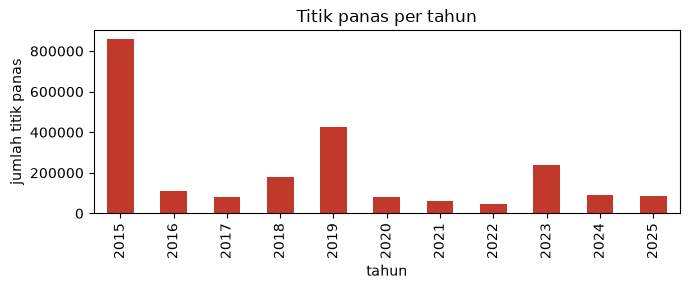

In [17]:
tren = con.execute("""
SELECT d.tahun, count(*) AS n_titik, count(*) FILTER (WHERE kepercayaan='tinggi') AS n_tinggi,
       round(avg(frp),2) AS frp_rata
FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) GROUP BY ALL ORDER BY 1""").df()
tren["x_median"] = (tren["n_titik"] / tren["n_titik"].median()).round(2)
display(tren)
ax = tren.plot.bar(x="tahun", y="n_titik", legend=False, figsize=(7, 3), color="#c0392b")
ax.set_ylabel("jumlah titik panas"); ax.set_title("Titik panas per tahun"); plt.tight_layout(); plt.show()

**Hasil dan interpretasi.** Median tahunan 89.945 titik.
* **2015** paling parah: 859.225 titik (**9,55× median**), 38% dari seluruh titik 11 tahun.
* **2019**: 424.511 (4,72×) dan **2023**: 236.111 (2,63×).
* Ketiganya (tahun El Niño) menyumbang 1.519.847 titik, sekitar **67%** dari total 2.252.966.
* Tahun lain berkisar 47 ribu (2022) sampai 181 ribu (2018). Tahun terbaru, 2024 (89.945) dan 2025 (83.276), tergolong biasa.

**Arti:** beban karhutla sangat timpang antar tahun. Rata-rata tahunan menyesatkan; yang menentukan adalah apakah tahun itu kering ekstrem. Ini juga alasan model diuji pada 2025 (tahun biasa) **dan** 2023 (tahun kering).

### Insight 2 — Musiman: bulan paling rawan
*Pertanyaan:* di bulan apa titik panas memuncak, dan apakah pola itu sama di semua provinsi? Grafik pertama = rata-rata titik per bulan antar tahun. Grafik kedua = peta panas per provinsi; tiap provinsi **dinormalkan ke puncaknya sendiri** (1,0 = bulan puncaknya) agar pola provinsi kecil tidak tertutup provinsi besar.

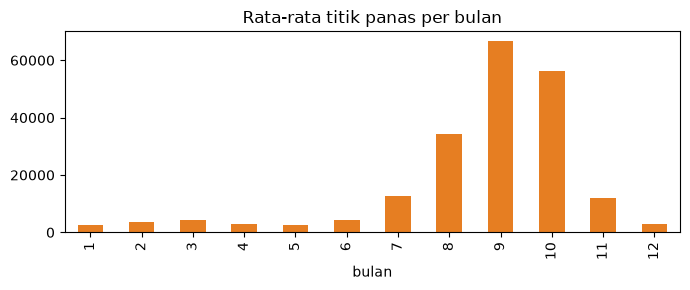

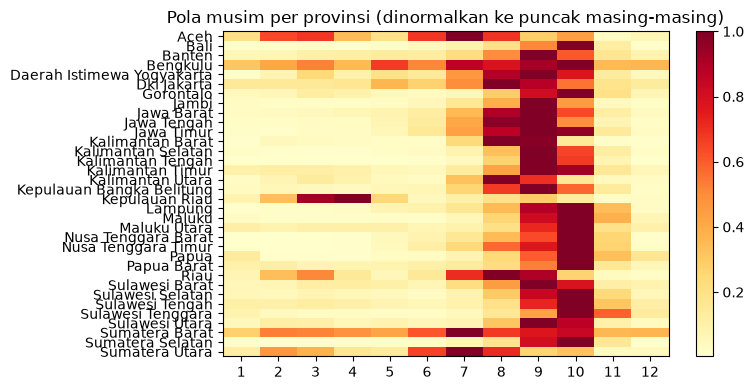

In [18]:
musim = con.execute("""
SELECT bulan, round(avg(n),0) AS rata_titik FROM (SELECT tahun, bulan, sum(n_titik) n FROM fact_wilayah_bulan GROUP BY ALL)
GROUP BY bulan ORDER BY bulan""").df()
ax = musim.plot.bar(x="bulan", y="rata_titik", legend=False, figsize=(7, 3), color="#e67e22")
ax.set_title("Rata-rata titik panas per bulan"); plt.tight_layout(); plt.show()

heat = con.execute("SELECT provinsi, bulan, sum(n_titik) n FROM v_provinsi_bulan GROUP BY ALL").df().pivot(index="provinsi", columns="bulan", values="n").fillna(0)
heat_n = heat.div(heat.max(axis=1).replace(0, np.nan), axis=0)       # tiap provinsi dinormalkan ke puncaknya sendiri
fig, ax = plt.subplots(figsize=(8, 4)); im = ax.imshow(heat_n.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(heat_n))); ax.set_yticklabels(heat_n.index); ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13))
ax.set_title("Pola musim per provinsi (dinormalkan ke puncak masing-masing)"); plt.colorbar(im); plt.tight_layout(); plt.show()

**Hasil dan interpretasi.**
* **Puncak: September** (kira-kira 65–70 ribu titik rata-rata per tahun), disusul **Oktober** (±55 ribu) dan **Agustus** (±35 ribu). Januari–Juni dan Desember rendah (sekitar 3–4 ribu per bulan); Juli dan November ±12 ribu.
* Peta panas: hampir seluruh provinsi di Kalimantan, Jawa, Sulawesi, Maluku, Nusa Tenggara, dan Papua memuncak pada **September–Oktober**.
* Beberapa provinsi punya **puncak berbeda**: Juli (Aceh, Sumatera Utara, Sumatera Barat), Maret–April (Kepulauan Riau), dan Riau memuncak di Agustus dengan puncak sekunder Februari–Maret. Artinya masa siaga tidak sama di seluruh Indonesia, dan "Agustus–Oktober" tidak berlaku untuk semuanya.

### Insight 3 — Wilayah teratas dan konsentrasi (prinsip Pareto)
*Pertanyaan:* berapa persen titik panas berasal dari 10 kabupaten teratas? Kalau konsentrasinya tinggi, sumber daya pencegahan bisa difokuskan. `pct_kumulatif` = persentase kumulatif dari kabupaten terbesar ke bawah.

In [19]:
top = con.execute("""
SELECT w.kabupaten, w.provinsi, sum(n_titik) AS n_titik
FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL ORDER BY n_titik DESC""").df()
top["pct_kumulatif"] = (top["n_titik"].cumsum() / top["n_titik"].sum() * 100).round(1)
print(f"10 kabupaten teratas = {top['pct_kumulatif'].iloc[9]}% dari seluruh titik panas ({len(top)} kabupaten)")
display(top.head(10))

10 kabupaten teratas = 31.5% dari seluruh titik panas (515 kabupaten)


,kabupaten,provinsi,n_titik,pct_kumulatif
0,Ogan Komering Ilir,Sumatera Selatan,147591.0,6.6
1,Merauke,Papua,133883.0,12.5
2,Pulang Pisau,Kalimantan Tengah,83078.0,16.2
3,Ketapang,Kalimantan Barat,77343.0,19.6
4,Musi Banyuasin,Sumatera Selatan,52477.0,21.9
5,Kotawaringin Timur,Kalimantan Tengah,49107.0,24.1
6,Kapuas,Kalimantan Tengah,48375.0,26.3
7,Seruyan,Kalimantan Tengah,46708.0,28.3
8,Sumba Timur,Nusa Tenggara Timur,36977.0,30.0
9,Kutai Timur,Kalimantan Timur,34786.0,31.5


**Hasil dan interpretasi.** 10 kabupaten dari 515 menyumbang **31,5%** seluruh titik. Teratas: **Ogan Komering Ilir** (147.591; 6,6%), **Merauke** (133.883), **Pulang Pisau** (83.078), **Ketapang** (77.343), Musi Banyuasin, Kotawaringin Timur, Kapuas, Seruyan, Sumba Timur, dan Kutai Timur.
Delapan dari sepuluh berada di Sumatera Selatan dan Kalimantan, kawasan yang dikenal bergambut, sedangkan Merauke dan Sumba Timur umumnya savana/lahan pertanian (pengetahuan umum, bukan hasil data ini). Jenis lahannya berbeda-beda, jadi penanganan yang cocok juga berbeda.

### Insight 4 — Awal dan akhir musim per provinsi
*Pertanyaan:* kapan 10% dan 90% titik panas tahunan sebuah provinsi terkumpul? Selisihnya = `panjang_hari`, "panjang musim api" efektif. Hanya provinsi dengan ≥ `AMBANG_ONSET` (1.000) titik per tahun yang dihitung; pada provinsi dengan titik sedikit, tanggal ini tidak bermakna. Bergesernya tanggal antar tahun bisa dipakai menyusun jadwal siaga. Tabel menampilkan 8 provinsi pertama (urut abjad).

In [20]:
onset = con.execute("SELECT * FROM v_onset_musim ORDER BY provinsi, tahun").df()
onset["panjang_hari"] = (pd.to_datetime(onset["akhir_musim"]) - pd.to_datetime(onset["mulai_musim"])).dt.days
display(onset.groupby("provinsi")[["panjang_hari"]].agg(["mean", "min", "max"]).round(0).head(8))

panjang_hari          
                    mean  min  max
provinsi                          
Aceh               202.0  130  255
Banten             163.0  163  163
Bengkulu           220.0  186  248
Gorontalo          128.0   61  180
Jambi              178.0   53  291
Jawa Barat         110.0   95  139
Jawa Tengah         94.0   68  115
Jawa Timur         109.0   75  199

**Hasil dan interpretasi.** Rata-rata panjang musim: Bengkulu 220 hari, Aceh 202, Jambi 178 (rentang 53–291), Gorontalo 128, Jawa Barat 110, Jawa Timur 109, Jawa Tengah 94.
* Provinsi Sumatera punya musim api yang **panjang dan bervariasi**; provinsi Jawa lebih **pendek (±100 hari)** dan terkonsentrasi.
* **Banten** hanya punya satu tahun yang memenuhi ambang (min = maks = 163), jadi angkanya tidak bermakna.
* Rentang lebar pada Jambi (53 sampai 291 hari) menunjukkan tahun-tahun biasa (api singkat) berbeda jauh dari tahun El Niño (api berlarut-larut).

### Insight 5 — Area kronis vs sporadis
*Pertanyaan:* sel 0,5° mana yang berapi hampir setiap tahun (kronis) dibanding yang hanya sekali-sekali? Sebuah sel dihitung "berapi" pada suatu tahun bila punya ≥ `AMBANG_KRONIS` titik (di sini **50**), supaya beberapa titik tersasar tidak ikut dihitung. Kelas ditentukan dari porsi tahun berapi: **sporadis** (≤ 3 dari 11 tahun), **berulang** (4–7 tahun), **kronis** (≥ 8 tahun, yaitu lebih dari 2/3 periode). Area kronis cocok untuk intervensi struktural (pengelolaan gambut, kanal), sporadis untuk patroli saat tahun kering.

*Catatan:* ambang 10 titik/tahun yang dicoba pertama terlalu rendah (70% sel menjadi "kronis"), sehingga dinaikkan ke 50.

In [21]:
n_tahun = con.execute("SELECT count(DISTINCT tahun) FROM dim_tanggal").fetchone()[0]
kronis = con.execute("SELECT * FROM v_sel_kronis").df()
kronis["kelas"] = pd.cut(kronis["tahun_berapi"] / n_tahun, [0, 0.34, 0.67, 1.01], labels=["sporadis", "berulang", "kronis"])
print(kronis.groupby("kelas", observed=True).agg(n_sel=("id_sel", "count"), total_titik=("total_titik", "sum")))

          n_sel  total_titik
kelas                       
sporadis    186     131465.0
berulang    189     660729.0
kronis      346    1444071.0


**Hasil dan interpretasi.** Dari 721 sel yang pernah berapi (≥ 50 titik pada setidaknya satu tahun):
* **kronis: 346 sel** (48%) menyumbang 1.444.071 titik (**65%** dari titik pada sel-sel ini);
* berulang: 189 sel, 660.729 titik;
* sporadis: 186 sel, 131.465 titik.

Hampir setengah area berapi bersifat menahun, dan sel menahun itu memuat dua pertiga titik. Prioritas pencegahan struktural paling efisien pada 346 sel ini, bukan pada seluruh area.

### Insight 6 — Siang vs malam dan tingkat kepercayaan
*Cara membaca:* hanya **perbandingan siang vs malam** yang sahih (jam lintasan satelit tetap). Titik malam cenderung dari api yang lebih besar/panas atau pembakaran yang sengaja dilakukan malam hari — sebagai petunjuk, bukan bukti. Makna `kepercayaan` berbeda antar wilayah, jadi dipakai untuk menyaring, bukan sebagai "kebenaran".

In [22]:
display(con.execute("""
SELECT siang_malam, kepercayaan, count(*) n, round(avg(frp),2) frp_rata
FROM fact_hotspot GROUP BY ALL ORDER BY 1, 2""").df())

,siang_malam,kepercayaan,n,frp_rata
0,malam,nominal,703335,3.04
1,malam,tinggi,10169,23.40
2,siang,nominal,1328620,9.44
3,siang,rendah,144894,12.12
4,siang,tinggi,65948,23.07


**Hasil dan interpretasi.**
* Siang: 1.539.462 titik (68%); malam: 713.504 (32%).
* FRP rata-rata titik **malam nominal hanya 3,04 MW**, jauh di bawah siang nominal (9,44 MW). Titik malam berkepercayaan tinggi justru kuat (23,40 MW), mirip siang tinggi (23,07 MW).
* Kelas `rendah` hanya muncul pada siang (144.894 titik); pada malam VIIRS tidak memberi kelas rendah.

FRP kecil di malam hari mungkin menandakan api yang lebih kecil atau membara dibanding api terbuka siang hari. Ini dugaan, bukan temuan yang dibuktikan data.

### Insight 7 — Intensitas api (FRP)
*Peringatan:* FRP (*Fire Radiative Power*, MW) VIIRS dapat dipercaya terutama untuk api kecil–menengah; api sangat besar bisa jenuh. Perlakukan sebagai indikator relatif, bukan ukuran emisi yang tepat. Histogram dipotong di 60 MW agar bentuk sebarannya terlihat.

FRP median / P90 / P99 (MW): [4.61, 16.06, 62.86]


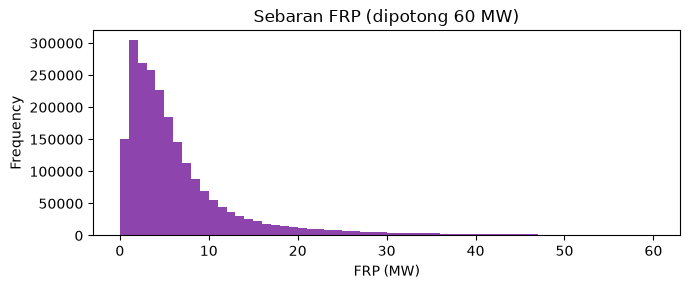

In [23]:
q = con.execute("SELECT quantile_cont(frp,[0.5,0.9,0.99]) FROM fact_hotspot").fetchone()[0]
print("FRP median / P90 / P99 (MW):", [round(x, 2) for x in q])
ax = con.execute("SELECT frp FROM fact_hotspot WHERE frp < 60").df()["frp"].plot.hist(bins=60, figsize=(7, 3), color="#8e44ad")
ax.set_xlabel("FRP (MW)"); ax.set_title("Sebaran FRP (dipotong 60 MW)"); plt.tight_layout(); plt.show()

**Hasil dan interpretasi.** FRP median **4,61 MW**, persentil ke-90 **16,06 MW**, persentil ke-99 **62,86 MW**. Sebaran sangat miring ke kanan: sebagian besar titik berintensitas rendah, dan sebagian kecil sangat intens. Karena itu rata-rata FRP kurang mewakili; median dan persentil lebih tepat. FRP juga tidak dipakai sebagai fitur utama model karena dampaknya kecil (lihat SHAP).

### Insight 8 — Hari-hari ekstrem
*Pertanyaan:* tanggal mana yang jumlah titiknya jauh melampaui hari biasa? Dasarnya **skor-z robust**: `0,6745 × (n − median) / MAD`, dengan median dan MAD (*median absolute deviation*) dihitung pada jendela bergulir 61 hari. Median dan MAD tahan terhadap pencilan, dan jendela bergulir berarti hari dibandingkan dengan musimnya sendiri, bukan dengan seluruh tahun.

In [24]:
harian = con.execute("SELECT tanggal, count(*) n FROM fact_hotspot GROUP BY 1 ORDER BY 1").df()
med = harian["n"].rolling(61, center=True, min_periods=15).median()
mad = (harian["n"] - med).abs().rolling(61, center=True, min_periods=15).median().replace(0, np.nan)
harian["z_robust"] = 0.6745 * (harian["n"] - med) / mad
display(harian.sort_values("z_robust", ascending=False).head(8))

,tanggal,n,z_robust
3552,2024-10-26,1376,13.812587
2249,2021-02-27,799,12.296654
2248,2021-02-26,689,11.260403
1538,2019-03-19,1243,10.524184
3553,2024-10-27,1077,10.086128
2144,2020-11-14,683,9.515919
3554,2024-10-28,1023,9.459060
3882,2025-09-24,3330,9.330583


**Hasil dan interpretasi.** Hari paling ekstrem secara relatif: **26 Okt 2024** (1.376 titik, z = 13,8), **27 Feb 2021** (799; 12,3), **19 Mar 2019** (1.243; 10,5), **14 Nov 2020**, dan **24 Sep 2025** (3.330 titik, jumlah harian terbesar pada daftar, namun z 9,3 karena terjadi di puncak musim).
Lonjakan di luar musim puncak (Feb 2021, Mar 2019) patut dicek ke wilayah dan berita lokal, karena bisa berupa kemarau singkat di Sumatera bagian utara atau kebakaran besar di satu lokasi.

### Insight 9 — Keterkaitan titik panas dengan luas terbakar
Bila `fact_luas_kebakaran` terisi (SiPongi), hitung rasio **luas per titik panas** (`ha_per_titik`). Nilai yang jauh berbeda antar provinsi menunjukkan perbedaan jenis lahan (savana, gambut, kebun) atau cakupan deteksi. Hanya kombinasi provinsi-tahun dengan **≥ 500 titik** yang dihitung, karena rasio pada titik sedikit sangat tidak stabil.

> **Catatan:** keluaran sel ini sengaja dikosongkan. `luas.csv` yang dipakai pada run sebelumnya dibuat dengan pemetaan Papua/Papua Barat yang tertukar, sehingga angkanya tidak boleh dipakai. Jalankan ulang sel konversi SiPongi (1C) dan sel ini.

In [25]:
n_luas = con.execute("SELECT count(*) FROM fact_luas_kebakaran").fetchone()[0]
if n_luas:
    display(con.execute("""
    SELECT l.tahun, l.provinsi, l.luas_ha, v.n_titik, round(l.luas_ha / nullif(v.n_titik,0), 1) AS ha_per_titik
    FROM fact_luas_kebakaran l JOIN (SELECT provinsi, tahun, sum(n_titik) n_titik FROM v_provinsi_bulan GROUP BY ALL) v
      ON v.provinsi = l.provinsi AND v.tahun = l.tahun
    WHERE v.n_titik >= 500                       -- abaikan provinsi-tahun bertitik sedikit (rasio tidak stabil)
    ORDER BY ha_per_titik DESC""").df().head(10))
else:
    print("fact_luas_kebakaran kosong — isi dari karhutla/raw/sipongi/luas.csv (tahun,provinsi,luas_ha) untuk insight ini.")

,tahun,provinsi,luas_ha,n_titik,ha_per_titik
0,2021,Nusa Tenggara Barat,101173.00,5231.0,19.3
1,2022,Maluku,14954.00,1044.0,14.3
2,2021,Nusa Tenggara Timur,137343.00,11155.0,12.3
3,2023,Kalimantan Selatan,190394.58,15972.0,11.9
4,2022,Nusa Tenggara Barat,30567.00,2871.0,10.6
5,2021,Maluku,11807.00,1169.0,10.1
6,2022,Nusa Tenggara Timur,70637.00,7260.0,9.7
7,2024,Nusa Tenggara Barat,46189.73,5039.0,9.2
8,2020,Papua Barat,5716.00,661.0,8.6
9,2024,Nusa Tenggara Timur,113089.51,13380.0,8.5


## Tahap 5 — Pemodelan

**Tujuan:** tiga model dengan tujuan berbeda, semuanya memakai data dari warehouse. Semua pembagian data **berdasarkan waktu** (bukan acak) agar model tidak "mengintip masa depan".

| Model | Jenis | Pertanyaan | Keluaran |
|---|---|---|---|
| 5A DBSCAN | *unsupervised* (klaster berbasis kepadatan) | Di mana "gugus api" besar tiap tahun? | tabel `hasil_cluster` |
| 5B K-Means | *unsupervised* (klaster berbasis jarak) | Kabupaten mana yang tergolong rawan tinggi/sedang/rendah/jarang? | tabel `hasil_tipologi` |
| 5C LightGBM | *supervised* (klasifikasi biner) | Area mana yang minggu depan akan muncul titik panas? | tabel `risiko_mingguan`, `hasil_evaluasi` |
| 5D SARIMA | deret waktu klasik | Apakah total titik bulanan bisa diperkirakan? | pembanding saja |

### 5A. Klaster spasial titik panas (DBSCAN)

**Tujuan:** menemukan *gugus api*, yaitu kumpulan titik panas yang saling berdekatan, pada musim puncak tiap tahun.

**Mengapa DBSCAN?** Tidak perlu menentukan jumlah klaster di muka (jumlah gugus api berbeda tiap tahun), bentuk klaster bebas (tidak harus bulat), dan titik tersasar otomatis ditandai *noise* (label −1) lalu dibuang.

**Cara kerja:** sebuah titik menjadi *inti* bila punya ≥ `min_samples` tetangga dalam radius `eps`; titik inti yang bersambung membentuk satu klaster; titik yang tidak terjangkau menjadi *noise*.

| Pengaturan | Nilai | Alasan |
|---|---|---|
| Data | `fact_hotspot`, bulan **Agustus–Oktober**, `kepercayaan ≠ rendah`, per tahun | musim puncak; titik berkepercayaan rendah lebih mungkin salah deteksi |
| Kolom | `latitude`, `longitude` (diubah ke radian) | hanya posisi yang menentukan kedekatan |
| `metric="haversine"`, `algorithm="ball_tree"` | jarak di permukaan bumi | jarak derajat tidak sama di setiap lintang |
| `eps` | 10 km ÷ 6371,0088 (radius bumi, km) = radian | titik dalam ±10 km dianggap satu gugus |
| `min_samples` | `MIN_SAMPEL_DBSCAN` = 15 | minimal 15 titik berdekatan agar disebut gugus |

**Catatan sampel:** bila titik setahun melebihi `CAP_DBSCAN` (400.000), diambil sampel acak (2015 memiliki titik terbanyak, rasio sampel 0,58). Agar kriteria kepadatan tetap setara antar tahun, `min_samples` diskalakan dengan rasio sampel, dan ukuran klaster (`n_titik`, `frp_sum`) dibagi rasio itu menjadi **perkiraan**; jumlah sebenarnya di sampel disimpan di `n_sampel`.

**Keluaran:** per klaster: tahun, pusat (`lat`, `lon`), `n_titik`, `frp_sum`, dan **nama kabupaten terdekat** dari pusat klaster (`sjoin_nearest` pada proyeksi metrik) agar mudah dibaca.

**Batas:** hasil peka terhadap `eps` dan `min_samples`. Titik dalam satu klaster tidak berarti satu kebakaran; klaster besar bisa gabungan beberapa kebakaran yang berdekatan.

In [26]:
from sklearn.cluster import DBSCAN
KM_BUMI = 6371.0088
hasil_cluster = []
pts = con.execute("""SELECT d.tahun, f.latitude, f.longitude, f.frp FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal)
                     WHERE f.kepercayaan <> 'rendah' AND d.bulan BETWEEN 8 AND 10""").df()
for th, g in pts.groupby("tahun"):
    n_all = len(g)
    if n_all > CAP_DBSCAN: g = g.sample(CAP_DBSCAN, random_state=SEED)
    rasio = len(g) / n_all
    ms = max(5, int(round(MIN_SAMPEL_DBSCAN * rasio)))                      # jaga kepadatan minimal tetap setara antar tahun
    lab = DBSCAN(eps=10 / KM_BUMI, min_samples=ms, metric="haversine", algorithm="ball_tree").fit_predict(np.radians(g[["latitude", "longitude"]]))
    g = g.assign(cluster=lab); g = g[g["cluster"] >= 0]
    r = g.groupby("cluster").agg(n_sampel=("frp", "size"), frp_sampel=("frp", "sum"), lat=("latitude", "mean"), lon=("longitude", "mean")).reset_index()
    r["n_titik"] = r["n_sampel"] / rasio; r["frp_sum"] = r["frp_sampel"] / rasio; r["rasio_sampel"] = rasio
    r.insert(0, "tahun", th); hasil_cluster.append(r.drop(columns="frp_sampel"))
hasil_cluster = pd.concat(hasil_cluster, ignore_index=True)
# beri nama daerah (kabupaten terdekat dari pusat klaster) agar mudah dipahami orang awam
_cp = gpd.GeoDataFrame(hasil_cluster[["lat", "lon"]], geometry=gpd.points_from_xy(hasil_cluster["lon"], hasil_cluster["lat"]), crs=4326).to_crs(3395)
_cw = gpd.sjoin_nearest(_cp, batas.to_crs(3395)[["wadmkk", "wadmpr", "geometry"]], how="left")
_cw = _cw[~_cw.index.duplicated(keep="first")]
hasil_cluster["kabupaten"] = _cw["wadmkk"].to_numpy(); hasil_cluster["provinsi"] = _cw["wadmpr"].to_numpy()
print(f"{len(hasil_cluster)} klaster | per tahun:", hasil_cluster.groupby("tahun").size().to_dict())
print("rasio sampel per tahun:", hasil_cluster.groupby("tahun")["rasio_sampel"].first().round(2).to_dict())
display(hasil_cluster.sort_values("n_titik", ascending=False).head(5))
con.register("hc_df", hasil_cluster); _ = con.execute("CREATE OR REPLACE TABLE hasil_cluster AS SELECT * FROM hc_df")

2798 klaster | per tahun: {2015: 288, 2016: 269, 2017: 268, 2018: 329, 2019: 287, 2020: 208, 2021: 195, 2022: 152, 2023: 275, 2024: 297, 2025: 230}
rasio sampel per tahun: {2015: 0.58, 2016: 1.0, 2017: 1.0, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0, 2025: 1.0}


,tahun,cluster,n_sampel,lat,lon,n_titik,frp_sum,rasio_sampel,kabupaten,provinsi
3,2015,3,186235,-2.035308,113.633133,320930.860512,2.381594e+06,0.580296,Katingan,Kalimantan Tengah
1,2015,1,120386,-2.505828,104.456576,207456.077395,1.769140e+06,0.580296,Banyu Asin,Sumatera Selatan
1156,2019,2,81766,-2.581169,113.886817,81766.000000,5.931335e+05,1.000000,Pulang Pisau,Kalimantan Tengah
1154,2019,0,69882,-2.561012,104.399579,69882.000000,6.763808e+05,1.000000,Banyu Asin,Sumatera Selatan
13,2015,13,26413,-7.551032,139.577619,45516.400347,3.973355e+05,0.580296,Merauke,Papua


**Hasil dan interpretasi.** 2.797 klaster dalam 11 tahun (152–329 per tahun; paling sedikit 2022, paling banyak 2018).
Gugus terbesar: **2015** di sekitar **Katingan** (±311.660 titik, perkiraan) dan **Banyu Asin** (±202.688), serta Merauke (±45.561); **2019** di sekitar **Pulang Pisau** (81.759) dan **Banyu Asin** (69.882).
Jadi pusat api terbesar berulang di dua wilayah, yaitu **Sumatera Selatan** dan **Kalimantan Tengah**. Angka 2015 adalah perkiraan karena data 2015 disampel (rasio 0,58).

### 5B. Tipologi kabupaten (K-Means)

**Tujuan:** mengelompokkan 515 kabupaten/kota menurut **ciri** kebakarannya, supaya penanganan bisa disesuaikan: pencegahan rutin untuk yang rawan tinggi, pemantauan saja untuk yang jarang terbakar.

**Mengapa K-Means?** Sederhana dan hasilnya mudah dijelaskan: tiap klaster punya rata-rata ciri yang bisa dibaca. Karena K-Means memakai jarak, ciri **distandarkan** dulu (`StandardScaler`: rata-rata 0, simpangan baku 1) agar ciri berskala besar tidak mendominasi.

**Ciri yang dipakai** (satu baris per kabupaten, dihitung dari `fact_wilayah_bulan`):

| Kolom | Rumus | Arti |
|---|---|---|
| `log_rata_tahunan` | `log(1 + rata-rata titik per tahun)` | tingkat keseringan; logaritma meredam kabupaten ekstrem |
| `variasi_antar_tahun` | simpangan baku ÷ rata-rata titik tahunan | seberapa berubah-ubah antar tahun (tinggi = kadang sangat parah) |
| `porsi_tahun_berapi` | porsi tahun dengan > 10 titik | kekerapan (ambang **tetap 10**, tidak mengikuti `AMBANG_KRONIS`) |
| `porsi_agu_okt` | titik Agu–Okt ÷ seluruh titik | ketajaman musim |
| `porsi_malam` | titik malam ÷ seluruh titik | kecenderungan api malam |
| `frp_per_titik` | total FRP ÷ jumlah titik | intensitas rata-rata api |

**Memilih K:** skor siluet (−1 sampai 1; makin tinggi, klaster makin terpisah) dihitung untuk K = 2…6. K = 2 paling tinggi secara statistik tetapi hanya memisahkan "tinggi" dan "rendah", terlalu kasar untuk dibaca. Karena itu **K = 4 dipaksa** lewat `K_TIPOLOGI`.

**Pemberian nama:** klaster diurutkan dari `log_rata_tahunan` rata-rata tertinggi ke terendah, lalu diberi nama **Rawan tinggi / Rawan sedang / Rawan rendah / Jarang terbakar**. Nama hanya mengikuti tingkat rata-rata, sehingga periksa isi tiap klaster sebelum dipakai dan ubah manual bila perlu.

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

fw = con.execute("""
SELECT w.wilayah_id, w.kabupaten, w.provinsi, f.tahun, f.bulan, f.n_titik, f.n_malam, f.frp_sum
FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id)""").df()
tahunan = fw.groupby(["wilayah_id", "tahun"])["n_titik"].sum().unstack(fill_value=0)
ciri = pd.DataFrame({
    "log_rata_tahunan": np.log1p(tahunan.mean(axis=1)),
    "variasi_antar_tahun": tahunan.std(axis=1) / tahunan.mean(axis=1).replace(0, np.nan),
    "porsi_tahun_berapi": (tahunan > 10).mean(axis=1),
})
ciri["porsi_agu_okt"] = (fw[fw["bulan"].between(8, 10)].groupby("wilayah_id")["n_titik"].sum() / fw.groupby("wilayah_id")["n_titik"].sum())
ciri["porsi_malam"] = fw.groupby("wilayah_id")["n_malam"].sum() / fw.groupby("wilayah_id")["n_titik"].sum()
ciri["frp_per_titik"] = fw.groupby("wilayah_id")["frp_sum"].sum() / fw.groupby("wilayah_id")["n_titik"].sum()
ciri = ciri.fillna(0)
X = StandardScaler().fit_transform(ciri)
sk = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=SEED).fit_predict(X)) for k in range(2, 7)}
K = K_TIPOLOGI; print("silhouette:", {k: round(v, 3) for k, v in sk.items()}, "| K dipakai =", K, "(parameter K_TIPOLOGI)")
ciri["klaster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(X)

# Nama klaster otomatis dari peringkat tingkat rata-rata & kekerapan (periksa & ubah manual sesuai konteks!)
ring = ciri.groupby("klaster")[["log_rata_tahunan", "porsi_tahun_berapi"]].mean()
urut = ring["log_rata_tahunan"].rank(ascending=False).astype(int)
NAMA_TINGKAT = ["Rawan tinggi", "Rawan sedang", "Rawan rendah", "Jarang terbakar"]          # bahasa awam untuk dashboard
nama = {k: (NAMA_TINGKAT[int(urut[k]) - 1] if K == 4 else f"Tingkat {int(urut[k])} dari {K}") for k in ring.index}
ciri["tipologi"] = ciri["klaster"].map(nama)
hasil_tipologi = ciri.reset_index().merge(fw[["wilayah_id", "kabupaten", "provinsi"]].drop_duplicates(), on="wilayah_id")
display(hasil_tipologi.groupby("tipologi")[list(ciri.columns[:6])].mean().round(2))
con.register("ht_df", hasil_tipologi); _ = con.execute("CREATE OR REPLACE TABLE hasil_tipologi AS SELECT * FROM ht_df")

silhouette: {2: 0.325, 3: 0.235, 4: 0.218, 5: 0.232, 6: 0.24} | K dipakai = 4 (parameter K_TIPOLOGI)


,log_rata_tahunan,variasi_antar_tahun,porsi_tahun_berapi,porsi_agu_okt,porsi_malam,frp_per_titik
tipologi,,,,,,
Jarang terbakar,1.60,1.49,0.15,0.58,0.25,4.25
Rawan rendah,4.33,0.82,0.89,0.69,0.32,4.23
Rawan sedang,5.03,0.76,0.95,0.51,0.10,7.72
Rawan tinggi,6.25,1.62,0.94,0.78,0.37,7.38


**Hasil dan interpretasi.** Silhouette: K=2 0,325; K=3 0,235; **K=4 0,218**; K=5 0,232; K=6 0,240 (K=4 dipilih manual meski bukan yang tertinggi; pemisahan klaster tergolong lemah, jadi batas antar-tipologi bersifat tegas di tabel tetapi kabur di kenyataan).

| Tipologi | Rata-rata titik/tahun | Berapi (porsi tahun) | Porsi Agu–Okt | Porsi malam | FRP/titik |
|---|---|---|---|---|---|
| Rawan tinggi | ≈ 518 | 0,94 | 0,78 | 0,37 | 7,38 |
| Rawan sedang | ≈ 152 | 0,95 | 0,51 | 0,10 | 7,72 |
| Rawan rendah | ≈ 75 | 0,89 | 0,69 | 0,32 | 4,23 |
| Jarang terbakar | ≈ 4 | 0,15 | 0,58 | 0,25 | 4,25 |

*Rata-rata titik/tahun* = `expm1` dari rata-rata `log_rata_tahunan` tiap kelompok (angka kira-kira, karena rata-rata dihitung pada skala log).
* **Rawan tinggi** juga paling berfluktuasi (variasi antar tahun 1,62), yaitu parah di tahun El Niño dan jauh lebih tenang di tahun lain, serta paling terkonsentrasi di Agu–Okt (78%).
* **Rawan sedang** menarik: hampir selalu berapi (95% tahun) tetapi musimnya tidak setajam itu (51% di Agu–Okt) dan jarang malam hari (10%). Profilnya berbeda dari gambut tinggi, jadi mungkin jenis lahan berbeda (dugaan).
* **Jarang terbakar**: hanya berapi 15% tahun, rata-rata ±4 titik per tahun.

### 5C. Prediksi risiko mingguan per sel 0,5° (LightGBM)

**Pertanyaan:** pada akhir minggu *t*, sel mana yang **akan punya ≥ 1 titik panas di minggu *t+1***? Hasilnya skor risiko (peluang 0–1) untuk memprioritaskan patroli.

**Jenis masalah:** klasifikasi biner yang dirumuskan sebagai prakiraan deret waktu. Setiap contoh = satu sel pada satu minggu; fitur dibuat dari **riwayat** (*lag features*); pembagian data mengikuti waktu. Ini bukan model deret waktu klasik seperti SARIMA: LightGBM tidak melihat urutan secara langsung, "ingatan" waktunya datang dari kolom riwayat di bawah.

**Target (label):** `y = 1` bila sel itu punya ≥ 1 titik panas pada minggu berikutnya (`n_titik` minggu *t+1* > 0), selain itu `y = 0`. Baris minggu terakhir (tanpa minggu berikutnya) dibuang. Proporsi `y = 1` pada data uji 2025 sekitar 20,6%, jadi kelas positif jarang.

**Fitur** (15 kolom, semuanya hanya memakai informasi sampai akhir minggu *t*):

| Kolom | Cara menghitung | Mengapa berguna |
|---|---|---|
| `n_1m`, `n_2m`, `n_4m`, `n_8m`, `n_26m` | jumlah titik pada 1, 2, 4, 8, 26 minggu terakhir (termasuk minggu *t*). Huruf *m* = minggu | api cenderung berlanjut dan berkelompok; beberapa jendela menangkap tren pendek sampai setengah tahun |
| `frp_rata_4m` | total FRP 4 minggu ÷ jumlah titik 4 minggu (0 bila tak ada titik) | api yang intens mungkin lebih bertahan |
| `porsi_tinggi_4m` | porsi titik berkepercayaan tinggi dalam 4 minggu | kualitas deteksi |
| `porsi_malam_4m` | porsi titik malam dalam 4 minggu | jenis api (membara/malam) |
| `minggu_sejak_api` | jumlah minggu sejak terakhir sel berapi (0 bila minggu *t* berapi; 99 bila belum pernah) | **kebaruan** api: sinyal terkuat |
| `sin_musim`, `cos_musim` | `sin` dan `cos` dari `2π × minggu ISO ke-(t+1) ÷ 52` | musim sebagai lingkaran, sehingga minggu 52 dan minggu 1 bertetangga |
| `lat_tengah`, `lon_tengah` | titik tengah sel | perbedaan karakter antar wilayah |
| `hujan_1bln` | rata-rata hujan (mm) bulan lengkap terakhir sebelum bulan minggu *t* | kekeringan jangka pendek |
| `hujan_3bln` | jumlah hujan 3 bulan lengkap terakhir | kekeringan menahun |

**Pencegahan kebocoran data (*data leakage*):**
* fitur riwayat memakai `cumsum` per sel sampai minggu *t*, tidak ada nilai masa depan;
* hujan hanya memakai bulan yang **sudah selesai** sebelum minggu *t* (`pm = bulan(t) − 1`);
* sel yang dimasukkan = sel yang pernah berapi di **periode latih** saja;
* pembagian berdasarkan **tahun minggu target**, tanpa pengacakan baris.

**Periode model:** mulai `MODEL_AWAL` (2019, mengikuti awal data hujan); bagian lain notebook memakai seluruh riwayat, dan fitur riwayat tetap dihitung dari data penuh.

**Pembagian waktu:** latih sampai `TAHUN_VAL − 1` (2023), validasi `TAHUN_VAL` (2024; untuk *early stopping* dan kalibrasi), uji `TAHUN_UJI` (2025; tidak pernah dipakai untuk memilih apa pun).

**Pembanding wajib:** *persistence* (skor = `n_1m`, "minggu depan sama dengan minggu ini") dan *klimatologi* (rata-rata `y` historis sel itu pada minggu-tahun yang sama di data latih). Model hanya berguna bila mengalahkan keduanya.

In [28]:
df = con.execute("SELECT * FROM fact_sel_minggu ORDER BY id_sel, minggu_mulai").df()
df["minggu_mulai"] = pd.to_datetime(df["minggu_mulai"])
g = df.groupby("id_sel")

def jumlah_geser(kolom, w):           # jumlah w minggu terakhir (termasuk minggu t), vektorisasi via cumsum
    cs = g[kolom].cumsum()
    return cs - cs.groupby(df["id_sel"]).shift(w).fillna(0)

for w in (1, 2, 4, 8, 26):
    df[f"n_{w}m"] = jumlah_geser("n_titik", w)
n4 = df["n_4m"].replace(0, np.nan)
df["frp_rata_4m"] = (jumlah_geser("frp_sum", 4) / n4).fillna(0)
df["porsi_tinggi_4m"] = (jumlah_geser("n_tinggi", 4) / n4).fillna(0)
df["porsi_malam_4m"] = (jumlah_geser("n_malam", 4) / n4).fillna(0)
k = g.cumcount(); terakhir = k.where(df["n_titik"] > 0).groupby(df["id_sel"]).ffill()
df["minggu_sejak_api"] = (k - terakhir).fillna(99)

sel = con.execute("SELECT * FROM dim_sel").df()
df = df.merge(sel, on="id_sel")
df["minggu_target"] = df["minggu_mulai"] + pd.Timedelta(days=7)
woy = df["minggu_target"].dt.isocalendar().week.astype(int)
df["woy_target"] = woy
df["sin_musim"], df["cos_musim"] = np.sin(2 * np.pi * woy / 52), np.cos(2 * np.pi * woy / 52)
df["y"] = (g["n_titik"].shift(-1).reindex(df.index) > 0).astype(float)          # target: ada api minggu depan
df.loc[g["n_titik"].shift(-1).reindex(df.index).isna(), "y"] = np.nan
df = df.dropna(subset=["y"]).copy(); df["y"] = df["y"].astype(int)

# --- hujan bulanan opsional (hujan_bulanan.parquet: id_sel, tahun, bulan, hujan_mm).
# Hanya bulan yang SUDAH SELESAI sebelum minggu t yang dipakai (tidak mengintip hari setelah minggu t):
#   hujan_1bln = hujan bulan sebelum bulan minggu t; hujan_3bln = jumlah 3 bulan sebelumnya.
FITUR = ["n_1m", "n_2m", "n_4m", "n_8m", "n_26m", "frp_rata_4m", "porsi_tinggi_4m", "porsi_malam_4m",
         "minggu_sejak_api", "sin_musim", "cos_musim", "lat_tengah", "lon_tengah"]
f_hujan = RAW/"hujan"/"hujan_bulanan.parquet"
PAKAI_HUJAN = False
if f_hujan.exists():
    h = pd.read_parquet(f_hujan)
    h["p"] = pd.to_datetime(dict(year=h["tahun"], month=h["bulan"], day=1)).dt.to_period("M")
    lebar = h.pivot_table(index="p", columns="id_sel", values="hujan_mm", aggfunc="mean")
    lebar = lebar.reindex(pd.period_range(lebar.index.min(), lebar.index.max(), freq="M"))       # bulan yang hilang → NaN
    h3 = lebar.rolling(3, min_periods=3).sum()
    a1 = lebar.stack().rename("hujan_1bln").reset_index(); a1.columns = ["pm", "id_sel", "hujan_1bln"]
    a3 = h3.stack().rename("hujan_3bln").reset_index(); a3.columns = ["pm", "id_sel", "hujan_3bln"]
    df["pm"] = df["minggu_mulai"].dt.to_period("M") - 1                                          # bulan terakhir yang sudah selesai
    df = df.merge(a1, on=["pm", "id_sel"], how="left").merge(a3, on=["pm", "id_sel"], how="left").drop(columns="pm")
    FITUR += ["hujan_1bln", "hujan_3bln"]; PAKAI_HUJAN = True
    print(f"fitur hujan dipakai | tercakup: {df['hujan_3bln'].notna().mean():.0%} baris (sisanya NaN, ditangani LightGBM)")
else:
    print("hujan tidak ada → model tanpa fitur hujan (hasil biasanya lebih lemah di musim kering awal)")

# --- batasi MODEL ke periode MODEL_AWAL dst. (fitur riwayat di atas sudah dihitung dari seluruh data, jadi awal 2019 tidak "kekurangan" riwayat)
n_sebelum = len(df)
df = df[df["minggu_mulai"] >= pd.Timestamp(MODEL_AWAL)].copy()
print(f"periode model: {df['minggu_mulai'].min().date()} → {df['minggu_mulai'].max().date()} | baris {n_sebelum:,} → {len(df):,}")
if PAKAI_HUJAN:
    cakup = df.groupby(df["minggu_target"].dt.year)["hujan_3bln"].apply(lambda s: s.notna().mean()).round(2)
    print("cakupan fitur hujan per tahun:", cakup.to_dict())
    kurang = [int(t) for t in (TAHUN_VAL, TAHUN_UJI) if cakup.get(t, 0) < 0.8]
    if kurang: print(f"PERINGATAN: tahun {kurang} punya data hujan < 80% — lengkapi berkas hujan atau hasil model tidak bisa dipercaya")

th = df["minggu_target"].dt.year
latih, valid, uji = df[th < TAHUN_VAL], df[th == TAHUN_VAL], df[th == TAHUN_UJI]
print(f"baris latih/valid/uji: {len(latih):,} / {len(valid):,} / {len(uji):,} | prevalensi positif uji: {uji['y'].mean():.3f}")

fitur hujan dipakai | tercakup: 63% baris (sisanya NaN, ditangani LightGBM)
periode model: 2019-01-07 → 2025-12-15 | baris 590,876 → 374,979
cakupan fitur hujan per tahun: {2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0, 2025: 1.0}
baris latih/valid/uji: 267,547 / 54,749 / 52,683 | prevalensi positif uji: 0.206


**Hasil pembentukan fitur.** Periode model 2019-01-07 sampai 2025-12-15; baris dikurangi dari 590.876 menjadi **374.979** setelah dibatasi ke `MODEL_AWAL`. Pembagian: latih **267.547**, validasi **54.749**, uji **52.683** baris; prevalensi positif uji **0,206**.
Pesan "fitur hujan dipakai | tercakup 63%" menghitung seluruh baris 2015–2025, dan **63% itu muncul karena hujan baru ada sejak Okt 2018**. Dalam periode model (2019–2025) cakupannya **100% tiap tahun**, jadi tidak ada data hujan yang hilang saat latih/validasi/uji.

**Fungsi evaluasi dan pengaturan model** (sel berikut hanya mendefinisikan, tanpa keluaran):

**LightGBM** (*gradient boosting* pohon keputusan): membangun pohon satu per satu, tiap pohon baru memperbaiki kesalahan pohon sebelumnya. Dipilih karena (1) cocok untuk data tabel dengan hubungan non-linear dan interaksi antar fitur, (2) menangani nilai kosong (`NaN`) langsung, (3) cepat pada 375 ribu baris.

| Pengaturan | Nilai | Arti |
|---|---|---|
| `n_estimators` | 600 | batas atas jumlah pohon (dihentikan lebih awal oleh *early stopping*) |
| `learning_rate` | 0,05 | langkah belajar kecil, lebih stabil, butuh banyak pohon |
| `num_leaves` | 31 | kompleksitas tiap pohon |
| `min_child_samples` | 40 | minimal baris per daun; mencegah pohon menghafal contoh langka |
| `subsample` / `subsample_freq` | 0,8 / 1 | tiap pohon memakai 80% baris acak (mengurangi *overfitting*) |
| `colsample_bytree` | 0,8 | tiap pohon memakai 80% fitur acak |
| *early stopping* | 40 putaran, metrik `average_precision` pada data **validasi** | berhenti bila PR-AUC validasi tidak membaik 40 pohon berturut-turut |
| `random_state` | `SEED` = 42 | hasil dapat diulang |
| bobot kelas | tidak dipakai | prevalensi ±20% cukup seimbang, dan peluang tetap bermakna untuk dikalibrasi |

**Kalibrasi (regresi isotonik):** skor mentah LightGBM tidak selalu bisa dibaca sebagai peluang. Regresi isotonik (pemetaan monoton) dilatih pada **validasi** untuk menyelaraskan skor dengan frekuensi kejadian sebenarnya, lalu diterapkan ke skor uji. Hasilnya bisa tepat 1,0 di ujung atas (sifat isotonik), jadi jangan dibaca sebagai kepastian.

**Fungsi `latih_evaluasi(thn_uji)`** melatih ulang seluruh prosedur untuk satu tahun uji: latih sampai `thn_uji − 2`, validasi `thn_uji − 1`, uji `thn_uji`. Dipakai untuk tahun uji utama dan tahun uji ekstra.

In [29]:
import lightgbm as lgb
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression
rng = np.random.default_rng(SEED)
K10 = max(1, int(0.10 * df["id_sel"].nunique()))          # "10% sel teratas" (bukan K=50 tetap, yang dibatasi jumlah sel berapi)

def _per_minggu(data, skor):
    d = data[["minggu_target", "y"]].assign(s=skor + rng.uniform(0, 1e-9, len(data)))       # pemecah seri acak
    return [x for _, x in d.groupby("minggu_target") if x["y"].sum() > 0]                     # hanya minggu yang ada sel berapi

def recall_at_k(data, skor, K):
    """Per minggu: dari semua sel yang benar-benar berapi, berapa % tertangkap di K sel skor tertinggi. Rata-rata antar minggu."""
    return float(np.mean([x.nlargest(K, "s")["y"].sum() / x["y"].sum() for x in _per_minggu(data, skor)]))

def presisi_at_k(data, skor, K):
    """Per minggu: dari K sel skor tertinggi, berapa % yang benar-benar berapi. Rata-rata antar minggu."""
    return float(np.mean([x.nlargest(K, "s")["y"].mean() for x in _per_minggu(data, skor)]))

def latih_evaluasi(thn_uji):
    """Latih sampai thn_uji-2, validasi thn_uji-1, uji thn_uji. Mengembalikan tabel metrik + objek model."""
    thn_val = thn_uji - 1
    th = df["minggu_target"].dt.year
    latih, valid, uji = df[th < thn_val], df[th == thn_val], df[th == thn_uji]
    if min(len(latih), len(valid), len(uji)) == 0 or latih["y"].sum() == 0:
        return None, None
    # Pembanding 1 (persistence): skor = jumlah titik minggu ini; "minggu depan sama dengan minggu ini".
    persist = uji["n_1m"].to_numpy(float)
    # Pembanding 2 (klimatologi): rata-rata y historis sel itu pada minggu-tahun yang sama, hanya dari data LATIH.
    klim_tab = latih.groupby(["id_sel", "woy_target"])["y"].mean()
    klim = np.nan_to_num(uji.set_index(["id_sel", "woy_target"]).index.map(klim_tab).to_numpy(dtype=float), nan=0.0)
    # LightGBM = boosting pohon keputusan. n_estimators=600 adalah batas atas (dihentikan lebih awal oleh early stopping);
    # learning_rate kecil = belajar bertahap; num_leaves = kompleksitas pohon; min_child_samples = minimal baris per daun;
    # subsample/colsample_bytree = 80% baris/fitur acak per pohon (mengurangi overfitting). Penjelasan lengkap di sel markdown sebelumnya.
    model = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=31, min_child_samples=40,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    model.fit(latih[FITUR], latih["y"], eval_set=[(valid[FITUR], valid["y"])], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(40, verbose=False)])
    # Kalibrasi: regresi isotonik dilatih pada VALIDASI agar skor bisa dibaca sebagai peluang, lalu diterapkan ke skor uji.
    iso = IsotonicRegression(out_of_bounds="clip").fit(model.predict_proba(valid[FITUR])[:, 1], valid["y"])   # kalibrasi pada validasi
    p_uji = model.predict_proba(uji[FITUR])[:, 1]; p_kal = iso.predict(p_uji)
    p0 = uji["y"].mean(); ref = p0 * (1 - p0)                       # Brier "tanpa kemampuan" (selalu menebak prevalensi)
    def baris(nama, skor, prob):
        b = brier_score_loss(uji["y"], skor) if prob else np.nan
        return dict(tahun_uji=thn_uji, model=nama, pr_auc=average_precision_score(uji["y"], skor),
                    recall_10persen_sel=recall_at_k(uji, skor, K10), presisi_at_50=presisi_at_k(uji, skor, 50),
                    brier=b, bss=(1 - b / ref) if prob else np.nan, prevalensi_uji=p0)
    tabel = pd.DataFrame([baris("Persistence", persist, False), baris("Klimatologi", klim, True),
                          baris("LightGBM", p_uji, True), baris("LightGBM + kalibrasi", p_kal, True)]).round(4)
    return tabel, dict(model=model, uji=uji, p_kal=p_kal, pohon=model.best_iteration_)

**Evaluasi di data uji.** Karena kelas positif hanya ±20%, **akurasi tidak dipakai** (menebak "tidak ada titik panas" terus sudah benar ±80%). Metrik:
* **PR-AUC** (luas di bawah kurva *precision–recall*): ukuran utama untuk kelas jarang. Tebakan acak ≈ prevalensi (0,206 pada 2025). Makin tinggi makin baik, maksimum 1.
* **recall pada 10% sel teratas** (`recall_10persen_sel`): tiap minggu, dari semua sel yang benar-benar berapi, berapa persen tertangkap di 10% sel dengan skor tertinggi (K10 = 103 sel). Maksimum yang mungkin tidak 100%: rata-rata ±213 sel (20,6% dari 1.033) berapi tiap minggu, sedangkan hanya 103 sel yang boleh ditandai, jadi batas atasnya ±0,48.
* **presisi@50** (`presisi_at_50`): tiap minggu, dari 50 sel dengan skor tertinggi, berapa persen yang benar-benar berapi. (Recall@50 tidak dipakai karena dibatasi oleh K, bukan oleh kualitas model.)
* **Brier** = rata-rata kuadrat selisih peluang dan kejadian (0 = sempurna). **BSS** (*Brier skill score*) = 1 − Brier / Brier-acuan; 0 = tak lebih baik dari menebak prevalensi, 1 = sempurna.

Tahun uji utama = `TAHUN_UJI` (2025). Tahun di `TAHUN_UJI_EKSTRA` (2023) dievaluasi juga dengan melatih ulang (latih ≤ 2021, validasi 2022), agar terlihat kinerja pada **tahun kering**, bukan hanya tahun biasa.
*Catatan:* sel dipilih dengan data sampai `TAHUN_VAL − 1`; untuk tahun uji ekstra yang lebih awal, ada sedikit informasi masa depan dalam pemilihan sel, jadi hasilnya perkiraan.

In [30]:
hasil_utama, obj = latih_evaluasi(TAHUN_UJI)
model, uji, p_kal = obj["model"], obj["uji"], obj["p_kal"]
print("tahun uji utama:", TAHUN_UJI, "| pohon terpakai:", obj["pohon"], "| baris uji:", f"{len(uji):,}", "| K10 =", K10)
ekstra = []
for t in TAHUN_UJI_EKSTRA:
    if t == TAHUN_UJI: continue
    tb, _ = latih_evaluasi(t)
    if tb is not None: ekstra.append(tb)
hasil_evaluasi = pd.concat([hasil_utama] + ekstra, ignore_index=True)
display(hasil_evaluasi)
_ = con.register("he_df", hasil_evaluasi); _ = con.execute("CREATE OR REPLACE TABLE hasil_evaluasi AS SELECT * FROM he_df")

tahun uji utama: 2025 | pohon terpakai: 380 | baris uji: 52,683 | K10 = 103


,tahun_uji,model,pr_auc,recall_10persen_sel,presisi_at_50,brier,bss,prevalensi_uji
0,2025,Persistence,0.5007,0.2957,0.6392,NaN,NaN,0.2055
1,2025,Klimatologi,0.5308,0.2857,0.5718,0.1305,0.2006,0.2055
2,2025,LightGBM,0.6737,0.3389,0.7004,0.1056,0.3530,0.2055
3,2025,LightGBM + kalibrasi,0.6658,0.3425,0.6988,0.1057,0.3527,0.2055
4,2023,Persistence,0.6726,0.2542,0.7369,NaN,NaN,0.2930
5,2023,Klimatologi,0.5941,0.2303,0.6577,0.1592,0.2315,0.2930
6,2023,LightGBM,0.8044,0.2831,0.7862,0.1153,0.4435,0.2930
7,2023,LightGBM + kalibrasi,0.7969,0.2836,0.7869,0.1178,0.4315,0.2930


**Hasil dan interpretasi.** Pohon terpakai 382 (dari maksimum 600) pada tahun uji 2025.

| Tahun uji | Model | PR-AUC | Presisi@50 | Recall 10% sel | BSS |
|---|---|---|---|---|---|
| 2025 (acak ≈ 0,206) | Persistence | 0,501 | 0,639 | 0,296 | — |
| | Klimatologi | 0,531 | 0,572 | 0,286 | 0,201 |
| | **LightGBM** | **0,674** | **0,699** | **0,344** | **0,354** |
| | LightGBM + kalibrasi | 0,666 | 0,700 | 0,343 | 0,354 |
| 2023 (acak ≈ 0,293) | Persistence | 0,673 | 0,737 | 0,254 | — |
| | Klimatologi | 0,594 | 0,658 | 0,230 | 0,232 |
| | **LightGBM** | **0,804** | **0,783** | **0,283** | **0,443** |
| | LightGBM + kalibrasi | 0,796 | 0,782 | 0,283 | 0,431 |

* **LightGBM mengalahkan kedua pembanding pada kedua tahun** di semua metrik. PR-AUC sekitar **3,3× tebakan acak** pada 2025 dan 2,7× pada 2023.
* **Keunggulan atas persistence sedang:** presisi@50 naik sekitar 6 poin (0,639 → 0,699) pada 2025; recall naik dari 0,296 menjadi 0,344. Api di sel yang sama minggu lalu sudah menjadi petunjuk yang kuat.
* **Recall 0,344 perlu dibaca terhadap batas atas ±0,48**: model menangkap sekitar 70% dari yang mungkin.
* **Kalibrasi tidak membantu** (PR-AUC sedikit turun, BSS sama), jadi LightGBM tanpa kalibrasi sama baiknya. Kalibrasi tetap dipakai untuk skor di dashboard agar bisa dibaca sebagai peluang.
* **Fitur hujan tidak mengubah ketepatan secara berarti:** PR-AUC 2025 sebelumnya (tanpa hujan) 0,673, kini 0,674; 2023 0,805 vs 0,804.

**Cara membaca:** bila LightGBM tidak jelas lebih baik dari klimatologi/persistence (PR-AUC dan BSS), jangan dipakai untuk keputusan: kembali ke fitur (misalnya indeks El Niño/IOD, tutupan gambut) atau pakai klimatologi saja. Bandingkan baris tahun uji biasa dengan tahun ekstrem. Skor kalibrasi bisa bernilai tepat 1,0 di ujung atas (batas regresi isotonik); jangan ditafsirkan sebagai kepastian. Skor ini **bukan peringatan resmi**.

**Penjelasan fitur (SHAP).** SHAP menguraikan tiap prediksi menjadi sumbangan tiap fitur (berdasarkan nilai Shapley dari teori permainan). Rata-rata nilai mutlaknya di 2.000 baris uji acak menunjukkan **fitur mana yang paling mendorong skor**. Ini ukuran *pengaruh model*, bukan sebab-akibat di dunia nyata, dan bukan ukuran seberapa besar fitur menaikkan ketepatan.

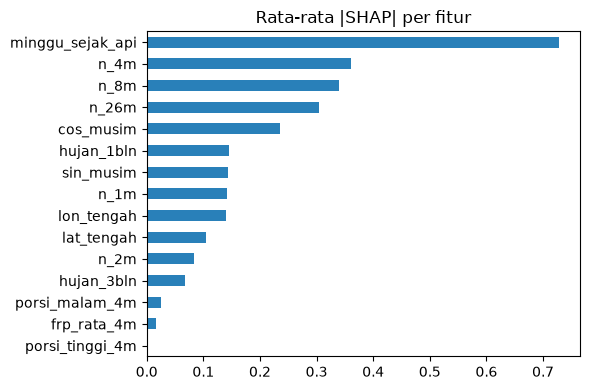

In [31]:
try:
    import shap
    contoh = uji[FITUR].sample(min(2000, len(uji)), random_state=SEED)
    sv = shap.TreeExplainer(model).shap_values(contoh)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv); sv = sv[..., 1] if sv.ndim == 3 else sv
    pent = pd.Series(np.abs(sv).mean(0), index=FITUR).sort_values()
    pent.plot.barh(figsize=(6, 4), color="#2980b9", title="Rata-rata |SHAP| per fitur"); plt.tight_layout(); plt.show()
except Exception as e:
    print("SHAP dilewati:", e); pd.Series(model.feature_importances_, index=FITUR).sort_values().plot.barh(figsize=(6, 4)); plt.show()

**Hasil dan interpretasi (SHAP).** Urutan pengaruh:
1. **`minggu_sejak_api`** paling berpengaruh (±0,73), jauh di atas yang lain: kebaruan api di sel itu adalah sinyal terkuat.
2. `n_4m` (±0,37), `n_8m` (±0,33), `n_26m` (±0,31): jumlah titik pada beberapa jendela waktu.
3. `cos_musim` (±0,24) dan `sin_musim` (±0,14): musim.
4. `lon_tengah` (±0,14), `hujan_1bln` (±0,14), `n_1m` (±0,13), `lat_tengah` (±0,11), `n_2m` (±0,09), `hujan_3bln` (±0,06).
5. `porsi_malam_4m`, `frp_rata_4m`, `porsi_tinggi_4m`: hampir tidak berpengaruh.

**Arti:** model terutama membaca *seberapa baru dan seberapa sering sel itu berapi, ditambah musim*. Hujan dipakai (`hujan_1bln` setara `lon_tengah`) namun tidak menambah ketepatan, kemungkinan karena informasi kekeringan sudah tertangkap lewat musim dan riwayat api. Intensitas dan kualitas deteksi (FRP, porsi tinggi/malam) nyaris tidak membantu.

**Simpan skor risiko periode uji ke gudang data** (tabel `risiko_mingguan`, dipakai halaman *Uji prakiraan model* di dashboard): untuk tiap sel dan minggu uji disimpan skor terkalibrasi (`skor`) dan kejadian sebenarnya (`y`). Ini simulasi ke masa lalu: minggu 2025 disembunyikan dari model, lalu prediksinya dicocokkan dengan kenyataan.

In [32]:
risiko = uji[["id_sel", "minggu_target", "lat_tengah", "lon_tengah", "y"]].copy()
risiko["skor"] = p_kal.round(4)
con.register("risiko_df", risiko); _ = con.execute("CREATE OR REPLACE TABLE risiko_mingguan AS SELECT * FROM risiko_df")
print(risiko.groupby("minggu_target")["skor"].max().sort_values(ascending=False).head(3))

minggu_target
2025-08-25    1.0
2025-08-18    1.0
2025-08-11    1.0
Name: skor, dtype: float64


### 5D. Perkiraan deret waktu bulanan — SARIMA (pembanding)

**Tujuan:** mengetahui apakah model deret waktu klasik bisa memperkirakan **total** titik panas bulanan nasional. Dipakai sebagai pembanding terhadap pendekatan per sel di 5C.

**Cara kerja:** SARIMA memodelkan nilai bulan ini dari nilai bulan-bulan sebelumnya (AR, MA) dan pola musiman tahunan. Di sini `order=(1,0,1)`, `seasonal_order=(1,1,0,12)` pada `log(1+n)` (meredam lonjakan). Latih pada seluruh bulan kecuali 12 bulan terakhir, lalu perkirakan 12 bulan itu. Pembanding: **naif** (nilai bulan yang sama tahun lalu). Bila SARIMA tidak lebih baik dari naif, ia tidak bernilai tambah.

In [33]:
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
except ImportError:
    SARIMAX = None; print("statsmodels belum terpasang → jalankan: %pip install statsmodels  (bagian ini opsional)")
if SARIMAX is not None:
    bulanan = con.execute("SELECT make_date(tahun, bulan, 1) AS t, sum(n_titik) AS n FROM fact_wilayah_bulan GROUP BY 1 ORDER BY 1").df().set_index("t")["n"]
    bulanan.index = pd.DatetimeIndex(bulanan.index, freq="MS")
    latih_s, uji_s = bulanan.iloc[:-12], bulanan.iloc[-12:]
    m = SARIMAX(np.log1p(latih_s), order=(1, 0, 1), seasonal_order=(1, 1, 0, 12), enforce_stationarity=False).fit(disp=False)
    pred = np.expm1(m.forecast(12)).clip(lower=0)
    mae_s = float(np.abs(pred.values - uji_s.values).mean()); mae_naif = float(np.abs(latih_s.iloc[-12:].values - uji_s.values).mean())
    print(f"MAE SARIMA: {mae_s:,.0f} | MAE naif (tahun lalu): {mae_naif:,.0f}  →", "SARIMA lebih baik" if mae_s < mae_naif else "SARIMA TIDAK lebih baik dari naif (hasil negatif; laporkan apa adanya)")

MAE SARIMA: 4,442 | MAE naif (tahun lalu): 3,620  → SARIMA TIDAK lebih baik dari naif (hasil negatif; laporkan apa adanya)


**Hasil dan interpretasi.** MAE SARIMA **4.442** titik per bulan, MAE naif **3.620**: **SARIMA tidak lebih baik dari naif** (hasil negatif, dilaporkan apa adanya). Penyebabnya wajar: total bulanan sangat dipengaruhi tahun ekstrem (El Niño), yang tidak bisa diperkirakan dari pola bulan-bulan sebelumnya. Ini alasan prakiraan dikerjakan per sel dengan fitur riwayat dan hujan (5C), bukan dengan deret waktu total.

## Tahap 6 — Dashboard (Streamlit), bahasa awam

**Tujuan:** menyajikan hasil agar bisa dibaca orang non-teknis, dan dapat di-*deploy* gratis.

Dashboard **tidak** membaca jutaan baris mentah atau DuckDB. Notebook mengekspor **tabel agregat kecil** ke `dashboard/data/*.parquet`; `app.py` hanya membaca berkas itu. Cepat, ringan, aman di-*deploy*.

**Prinsip desain:** kalimat temuan dibuat **otomatis** dari data (bukan angka mentah saja), istilah teknis diganti bahasa sehari-hari, setiap hasil model diberi **nama daerah**, dan rincian teknis disembunyikan di bagian "untuk yang ingin tahu lebih detail".

### 6.1 Ekspor agregat

| Berkas | Isi | Sumber |
|---|---|---|
| `prov_bulan`, `kab_tahun`, `grid_bulan`, `onset` | titik per provinsi/kabupaten/sel/musim | view dan fakta warehouse |
| `klaster`, `tipologi` | hasil DBSCAN dan K-Means | Tahap 5A dan 5B |
| `risiko`, `evaluasi` | skor mingguan uji dan metrik | Tahap 5C |
| `luas` | luas terbakar per provinsi-tahun | `luas.csv` (SiPongi) |
| `meta.json` | apakah hujan dipakai dan tahun awal model | konfigurasi |

Sel pertama memberi nama kabupaten untuk setiap sel model (kabupaten terdekat dari titik tengah sel); sel kedua mengekspor `luas`.

In [34]:
# nama daerah untuk setiap sel model (kabupaten terdekat dari titik tengah sel)
_sel = con.execute("SELECT id_sel, lat_tengah, lon_tengah FROM dim_sel").df()
_pt = gpd.GeoDataFrame(_sel, geometry=gpd.points_from_xy(_sel["lon_tengah"], _sel["lat_tengah"]), crs=4326).to_crs(3395)
_sw = gpd.sjoin_nearest(_pt, batas.to_crs(3395)[["wadmkk", "wadmpr", "geometry"]], how="left")
_sw = _sw[~_sw.index.duplicated(keep="first")]
sel_wilayah = _sw[["id_sel", "wadmkk", "wadmpr"]].rename(columns={"wadmkk": "kabupaten", "wadmpr": "provinsi"})
_ = con.register("sel_wilayah_df", sel_wilayah); _ = con.execute("CREATE OR REPLACE TABLE sel_wilayah AS SELECT * FROM sel_wilayah_df")

def ekspor(nama, sql):
    out = DASH/"data"/f"{nama}.parquet"
    df_ = con.execute(sql).df()
    df_.to_parquet(out, index=False)
    return nama, len(df_), round(out.stat().st_size / 1024, 1)

import json
(DASH/"data"/"meta.json").write_text(json.dumps({"pakai_hujan": bool(PAKAI_HUJAN), "model_awal": MODEL_AWAL[:4]}))
res_ekspor = [
 ekspor("prov_bulan", "SELECT * FROM v_provinsi_bulan"),
 ekspor("kab_tahun", """SELECT w.kdpkab, w.kabupaten, w.provinsi, f.tahun, sum(n_titik) AS n_titik, sum(n_tinggi) AS n_tinggi,
                         sum(n_malam) AS n_malam, sum(frp_sum) AS frp_sum
                         FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL"""),
 ekspor("grid_bulan", f"""SELECT id_sel_01 AS id_sel, tahun, bulan, n_titik, round(frp_sum,1) AS frp_sum,
                         (id_sel_01 // 10000 - 200 + 0.5) * {RES_HALUS} AS lat, (id_sel_01 % 10000 + 0.5) * {RES_HALUS} AS lon
                         FROM v_grid_bulan"""),
 ekspor("onset", "SELECT provinsi, tahun, mulai_musim, akhir_musim, total_titik FROM v_onset_musim"),
 ekspor("klaster", "SELECT * FROM hasil_cluster"),
 ekspor("tipologi", "SELECT wilayah_id, kabupaten, provinsi, tipologi, log_rata_tahunan, variasi_antar_tahun, porsi_tahun_berapi, porsi_agu_okt, porsi_malam, frp_per_titik FROM hasil_tipologi"),
 ekspor("risiko", """SELECT r.id_sel, r.minggu_target, r.lat_tengah AS lat, r.lon_tengah AS lon, r.y AS terjadi, r.skor, w.kabupaten, w.provinsi
                     FROM risiko_mingguan r LEFT JOIN sel_wilayah w USING (id_sel)"""),
 ekspor("evaluasi", "SELECT * FROM hasil_evaluasi"),
]
pd.DataFrame(res_ekspor, columns=["berkas", "baris", "KB"])

,berkas,baris,KB
0,prov_bulan,4336,61.8
1,kab_tahun,5239,92.0
2,grid_bulan,278078,1991.7
3,onset,251,9.3
4,klaster,2798,102.8
5,tipologi,515,37.3
6,risiko,52683,77.5
7,evaluasi,8,5.4


In [35]:
# luas terbakar (SiPongi) untuk halaman "Luas terbakar" di dashboard
f_luas = RAW/"sipongi"/"luas.csv"
if f_luas.exists():
    luas_df = pd.read_csv(f_luas)
    luas_df.to_parquet(DASH/"data"/"luas.parquet", index=False)
    print(f"luas.parquet: {len(luas_df)} baris | {luas_df['provinsi'].nunique()} provinsi | {luas_df['tahun'].min()}–{luas_df['tahun'].max()}")
else:
    print("luas.csv belum ada → halaman 'Luas terbakar' akan menampilkan pesan data belum tersedia")

luas.parquet: 204 baris | 34 provinsi | 2019–2024


### 6.2 Kode aplikasi — tujuh halaman

`%%writefile` menulis sel ini menjadi `dashboard/app.py`.

| Halaman | Isi |
|---|---|
| **Beranda** | total titik, tahun terparah, bulan rawan, tiga temuan utama |
| **Kapan terjadi?** | puncak musim, bulan puncak tiap provinsi, kalender panas |
| **Di mana terjadi?** | peta, 10 provinsi dan kabupaten teratas, pencarian kabupaten |
| **Luas terbakar** | luas terbakar (SiPongi) vs titik panas per tahun dan provinsi |
| **Daerah rawan** | tipologi kabupaten (K-Means) dan kawasan api terbesar (DBSCAN) |
| **Uji prakiraan model** | seberapa baik model menebak area rawan, dengan simulasi per minggu di masa lalu |
| **Tentang data** | sumber, arti istilah, dan keterbatasan |

Panel kiri memuat pilihan rentang tahun dan provinsi yang berlaku di sebagian besar halaman. Halaman *Uji prakiraan model* sengaja bukan "prakiraan minggu depan" sungguhan: data berhenti 31 Desember 2025, sehingga halaman itu menampilkan pengujian model pada 2025.

In [36]:
%%writefile dashboard/app.py
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="Titik Panas Karhutla Indonesia", layout="wide")
DATA = Path(__file__).parent / "data"
BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli", "Agustus", "September", "Oktober", "November", "Desember"]
BLN = [b[:3] for b in BULAN]

@st.cache_data
def muat(nama):
    return pd.read_parquet(DATA / f"{nama}.parquet")

def angka(n):
    n = float(n)
    if n >= 1e6: return f"{n / 1e6:.1f} juta".replace(".", ",")
    if n >= 1e3: return f"{n / 1e3:.0f} ribu"
    return f"{n:.0f}"

def persen(x):
    return f"{x * 100:.0f}%"

prov_bulan, kab_tahun, grid = muat("prov_bulan"), muat("kab_tahun"), muat("grid_bulan")
try:
    luas = muat("luas")
except Exception:
    luas = None
klaster, tipologi, risiko, evaluasi = muat("klaster"), muat("tipologi"), muat("risiko"), muat("evaluasi")
try:
    import json
    _meta = json.loads((DATA / "meta.json").read_text())
    PAKAI_HUJAN, MODEL_AWAL = _meta.get("pakai_hujan", False), _meta.get("model_awal", "")
except Exception:
    PAKAI_HUJAN, MODEL_AWAL = False, ""

st.sidebar.title("Titik Panas Karhutla")
halaman = st.sidebar.radio("Pilih halaman", ["Beranda", "Kapan terjadi?", "Di mana terjadi?", "Luas terbakar", "Daerah rawan", "Uji prakiraan model", "Tentang data"])
tahun_semua = sorted(prov_bulan["tahun"].unique())
rentang = st.sidebar.select_slider("Tahun yang ditampilkan", options=tahun_semua, value=(tahun_semua[0], tahun_semua[-1]))
pilih_prov = st.sidebar.multiselect("Batasi ke provinsi tertentu (kosong = semua)", sorted(prov_bulan["provinsi"].unique()))
st.sidebar.info("**Titik panas** = lokasi yang dilihat satelit lebih panas dari sekitarnya, kemungkinan ada api. "
                "Ini bukan jumlah kebakaran yang pasti. Penjelasan lengkap di halaman *Tentang data*.")

def saring(d):
    d = d[d["tahun"].between(*rentang)]
    return d[d["provinsi"].isin(pilih_prov)] if pilih_prov else d

pb, kt = saring(prov_bulan), saring(kab_tahun)
if pb.empty:
    st.warning("Tidak ada data untuk pilihan ini. Ubah tahun atau provinsi di panel kiri."); st.stop()

per_tahun = pb.groupby("tahun")["n_titik"].sum()
per_bulan = pb.groupby("bulan")["n_titik"].sum().reindex(range(1, 13), fill_value=0)
total = int(per_tahun.sum())
jendela = [per_bulan.iloc[i:i + 3].sum() for i in range(10)]            # 3 bulan berurutan dengan titik terbanyak
i3 = int(np.argmax(jendela)); porsi3 = jendela[i3] / max(per_bulan.sum(), 1)
prov_tot = pb.groupby("provinsi")["n_titik"].sum().sort_values(ascending=False)
kab_tot = kt.groupby(["kabupaten", "provinsi"], as_index=False)["n_titik"].sum().sort_values("n_titik", ascending=False)

# ------------------------------------------------------------------ BERANDA
if halaman == "Beranda":
    st.title("Titik Panas Karhutla Indonesia")
    st.write(f"Data satelit tahun **{rentang[0]}–{rentang[1]}**. Halaman ini merangkum **kapan** dan **di mana** titik panas paling banyak muncul.")
    k1, k2, k3 = st.columns(3)
    k1.metric("Total titik panas", angka(total))
    k2.metric("Tahun terparah", f"{int(per_tahun.idxmax())}"); k2.caption(f"{angka(per_tahun.max())} titik panas")
    k3.metric("Bulan paling rawan", f"{BLN[i3]}–{BLN[i3 + 2]}"); k3.caption(f"{persen(porsi3)} dari semua titik ({BULAN[i3]} sampai {BULAN[i3 + 2]})")

    st.subheader("Temuan utama")
    median = per_tahun.median()
    if len(per_tahun) >= 3 and median > 0:
        st.info(f"**Satu tahun bisa jauh lebih parah dari yang lain.** Tahun {int(per_tahun.idxmax())} mencatat {angka(per_tahun.max())} titik panas, "
                f"sekitar {per_tahun.max() / median:.0f} kali lipat tahun yang biasa ({angka(median)} titik).")
    st.info(f"**Musim rawan jelas.** Sekitar {persen(porsi3)} titik panas muncul hanya dalam 3 bulan: {BULAN[i3]} sampai {BULAN[i3 + 2]}.")
    if len(prov_tot) and len(kab_tot):
        top3 = prov_tot.head(3)
        st.info(f"**Terkonsentrasi di beberapa daerah.** Tiga provinsi teratas ({', '.join(top3.index)}) menyumbang {persen(top3.sum() / total)} dari semua titik. "
                f"Kabupaten teratas: {kab_tot.iloc[0]['kabupaten']} ({kab_tot.iloc[0]['provinsi']}).")
    d = per_tahun.reset_index(); d.columns = ["Tahun", "Titik panas"]
    d["Kategori"] = np.where(d["Titik panas"] >= 2 * median, "Sangat parah (≥ 2× biasa)", "Biasa")
    fig = px.bar(d, x="Tahun", y="Titik panas", color="Kategori", title="Jumlah titik panas per tahun",
                 color_discrete_map={"Sangat parah (≥ 2× biasa)": "#b30000", "Biasa": "#9ecae1"})
    fig.update_xaxes(type="category"); st.plotly_chart(fig, width="stretch")

# ------------------------------------------------------------------ KAPAN
elif halaman == "Kapan terjadi?":
    st.title("Kapan titik panas paling banyak?")
    st.info(f"**Puncaknya di {BULAN[i3]}–{BULAN[i3 + 2]}.** {persen(porsi3)} titik panas muncul di tiga bulan ini. "
            "Di luar musim itu jumlahnya jauh lebih sedikit.")
    rata = (pb.groupby(["tahun", "bulan"])["n_titik"].sum().groupby("bulan").mean().reindex(range(1, 13), fill_value=0)).reset_index()
    rata.columns = ["bulan", "rata"]; rata["Bulan"] = [BLN[b - 1] for b in rata["bulan"]]
    rata["Musim"] = np.where(rata["bulan"].between(i3 + 1, i3 + 3), "Puncak", "Lainnya")
    fig = px.bar(rata, x="Bulan", y="rata", color="Musim", title="Rata-rata titik panas per bulan (dihitung dari semua tahun terpilih)",
                 labels={"rata": "Titik panas"}, category_orders={"Bulan": BLN}, color_discrete_map={"Puncak": "#b30000", "Lainnya": "#9ecae1"})
    st.plotly_chart(fig, width="stretch")

    st.subheader("Bulan puncak tiap provinsi")
    pm = pb.groupby(["provinsi", "bulan"])["n_titik"].sum().reset_index()
    idx = pm.groupby("provinsi")["n_titik"].idxmax()
    tabel = pm.loc[idx].assign(**{"Bulan puncak": lambda x: [BULAN[b - 1] for b in x["bulan"]]})
    tabel = tabel.merge(prov_tot.rename("Total titik").reset_index(), on="provinsi").sort_values("Total titik", ascending=False)
    st.caption("Diurutkan dari provinsi dengan titik panas terbanyak. Provinsi bertitik sedikit sebaiknya tidak ditafsirkan.")
    st.dataframe(tabel[["provinsi", "Bulan puncak", "Total titik"]].rename(columns={"provinsi": "Provinsi"}).head(15), hide_index=True, width="stretch")

    with st.expander("Lihat tahun demi tahun (kalender panas)"):
        pivot = pb.groupby(["tahun", "bulan"])["n_titik"].sum().unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0)
        pivot.columns = BLN
        st.plotly_chart(px.imshow(pivot, aspect="auto", color_continuous_scale="YlOrRd", labels=dict(x="Bulan", y="Tahun", color="Titik panas"),
                                  title="Makin gelap = makin banyak titik panas"), width="stretch")

# ------------------------------------------------------------------ DI MANA
elif halaman == "Di mana terjadi?":
    st.title("Di mana titik panas paling banyak?")
    if len(prov_tot) and len(kab_tot):
        st.info(f"**{prov_tot.index[0]}** paling banyak ({angka(prov_tot.iloc[0])} titik, {persen(prov_tot.iloc[0] / total)} dari total). "
                f"Kabupaten teratas: **{kab_tot.iloc[0]['kabupaten']}**. Sepuluh kabupaten teratas menyumbang {persen(kab_tot.head(10)['n_titik'].sum() / total)} dari semua titik.")
    pilihan = st.radio("Bulan yang ditampilkan di peta", ["Musim rawan (3 bulan puncak)", "Semua bulan"], horizontal=True)
    b1, b2 = (i3 + 1, i3 + 3) if pilihan.startswith("Musim") else (1, 12)
    g = grid[grid["tahun"].between(*rentang) & grid["bulan"].between(b1, b2)].groupby(["id_sel", "lat", "lon"], as_index=False)["n_titik"].sum()
    g = g.rename(columns={"n_titik": "Titik panas"})
    if g.empty:
        st.info("Tidak ada data pada pilihan ini.")
    else:
        fig = px.scatter_map(g, lat="lat", lon="lon", size="Titik panas", color="Titik panas", color_continuous_scale="YlOrRd",
                             size_max=18, zoom=3.5, height=560, map_style="carto-positron", title="Makin besar dan gelap = makin banyak titik panas")
        st.plotly_chart(fig, width="stretch")
    c1, c2 = st.columns(2)
    with c1:
        p = prov_tot.head(10).sort_values().reset_index(); p.columns = ["Provinsi", "Titik panas"]
        st.plotly_chart(px.bar(p, x="Titik panas", y="Provinsi", orientation="h", title="10 provinsi teratas"), width="stretch")
    with c2:
        st.markdown("**10 kabupaten teratas**")
        t = kab_tot.head(10).copy(); t["Porsi dari total"] = (t["n_titik"] / total).map(persen)
        st.dataframe(t.rename(columns={"kabupaten": "Kabupaten/Kota", "provinsi": "Provinsi", "n_titik": "Titik panas"}), hide_index=True, width="stretch")
    st.subheader("Cari kabupaten/kota")
    pilih = st.selectbox("Kabupaten/Kota", sorted(kt["kabupaten"].unique()))
    s = kt[kt["kabupaten"] == pilih].groupby("tahun", as_index=False)["n_titik"].sum().rename(columns={"tahun": "Tahun", "n_titik": "Titik panas"})
    fig = px.bar(s, x="Tahun", y="Titik panas", title=f"{pilih}: titik panas per tahun"); fig.update_xaxes(type="category")
    st.plotly_chart(fig, width="stretch")

# ------------------------------------------------------------------ LUAS TERBAKAR
elif halaman == "Luas terbakar":
    st.title("Berapa luas lahan yang terbakar?")
    if luas is None or luas.empty:
        st.info("Data luas terbakar belum tersedia. Jalankan sel ekspor luas di notebook, lalu muat ulang halaman ini.")
        st.stop()
    JAKARTA_HA = 66000
    lt = luas[luas["tahun"].between(*rentang)]
    if pilih_prov:
        lt = lt[lt["provinsi"].isin(pilih_prov)]
    titik = prov_bulan.groupby(["tahun", "provinsi"], as_index=False)["n_titik"].sum()
    m = lt.merge(titik, on=["tahun", "provinsi"], how="left").fillna({"n_titik": 0})
    if m.empty:
        st.warning("Tidak ada data luas untuk pilihan ini. Data luas tersedia untuk tahun " f"{int(luas['tahun'].min())}–{int(luas['tahun'].max())}."); st.stop()
    st.write("Titik panas hanya menandai *ada api*. Halaman ini menambahkan **luas lahan yang terbakar** (hektare) dari data resmi SiPongi, "
             "supaya terlihat apakah banyak titik panas memang berarti lahan yang terbakar juga luas.")
    st.caption(f"Data luas tersedia untuk {int(m['tahun'].min())}–{int(m['tahun'].max())}. Satu hektare kira-kira satu lapangan sepak bola.")
    tot = m.groupby("tahun").agg(luas_ha=("luas_ha", "sum"), n_titik=("n_titik", "sum"))
    th_max = int(tot["luas_ha"].idxmax())
    k1, k2, k3 = st.columns(3)
    k1.metric("Total luas terbakar", f"{angka(tot['luas_ha'].sum())} ha")
    k2.metric("Tahun terluas", f"{th_max}"); k2.caption(f"{angka(tot['luas_ha'].max())} hektare")
    pt_ = m.groupby("provinsi")["luas_ha"].sum().sort_values(ascending=False)
    k3.metric("Provinsi terluas", pt_.index[0]); k3.caption(f"{angka(pt_.iloc[0])} hektare ({persen(pt_.iloc[0] / pt_.sum())} dari total)")

    st.subheader("Temuan utama")
    st.info(f"**Tahun terparah: {th_max}.** Sekitar {angka(tot['luas_ha'].max())} hektare terbakar, kira-kira "
            f"{tot['luas_ha'].max() / JAKARTA_HA:.0f} kali luas DKI Jakarta (±66 ribu hektare).")
    if len(tot) >= 4:
        r = tot["luas_ha"].rank().corr(tot["n_titik"].rank())      # korelasi peringkat (Spearman) tanpa scipy
        if r >= 0.7:
            st.info("**Banyak titik panas biasanya berarti lahan terbakar luas.** Tahun dengan titik panas terbanyak umumnya juga tahun dengan lahan terbakar terluas, "
                    "jadi titik panas cukup berguna sebagai petunjuk tingkat keparahan satu tahun.")
        elif r >= 0.4:
            st.info("**Hubungannya ada, tapi tidak kuat.** Tahun dengan banyak titik panas cenderung punya lahan terbakar lebih luas, tetapi ada banyak pengecualian.")
        else:
            st.warning("**Jumlah titik panas kurang mencerminkan luas terbakar** pada data ini. Jangan memakai titik panas sebagai pengganti luas.")
    n_min = 500
    rasio = m[m["n_titik"] >= n_min].assign(ha_per_titik=lambda x: x["luas_ha"] / x["n_titik"])
    if len(rasio) >= 5:
        hi, lo = rasio.loc[rasio["ha_per_titik"].idxmax()], rasio.loc[rasio["ha_per_titik"].idxmin()]
        st.info(f"**Satu titik panas bisa berarti luas yang sangat berbeda.** Di {hi['provinsi']} ({int(hi['tahun'])}) rata-rata {hi['ha_per_titik']:.0f} hektare per titik, "
                f"sedangkan di {lo['provinsi']} ({int(lo['tahun'])}) hanya {lo['ha_per_titik']:.1f} hektare per titik. "
                "Karena itu angka titik panas sebaiknya dipakai untuk membandingkan, bukan untuk menghitung luas.")

    c1, c2 = st.columns(2)
    d1 = tot.reset_index()
    with c1:
        f = px.bar(d1, x="tahun", y="n_titik", title="Titik panas per tahun", labels={"tahun": "Tahun", "n_titik": "Titik panas"}, color_discrete_sequence=["#9ecae1"])
        f.update_xaxes(type="category"); st.plotly_chart(f, width="stretch")
    with c2:
        f = px.bar(d1, x="tahun", y="luas_ha", title="Luas terbakar per tahun (hektare)", labels={"tahun": "Tahun", "luas_ha": "Hektare"}, color_discrete_sequence=["#b30000"])
        f.update_xaxes(type="category"); st.plotly_chart(f, width="stretch")

    st.subheader("Provinsi dengan lahan terbakar terluas")
    tp = m.groupby("provinsi").agg(luas_ha=("luas_ha", "sum"), n_titik=("n_titik", "sum")).sort_values("luas_ha", ascending=False).head(10).reset_index()
    tp["Hektare per titik"] = np.where(tp["n_titik"] > 0, tp["luas_ha"] / tp["n_titik"].replace(0, np.nan), np.nan).round(1)
    tp["Porsi dari total"] = (tp["luas_ha"] / m["luas_ha"].sum()).map(persen)
    st.dataframe(tp.assign(luas_ha=tp["luas_ha"].round(0), n_titik=tp["n_titik"].round(0))
                 .rename(columns={"provinsi": "Provinsi", "luas_ha": "Luas terbakar (ha)", "n_titik": "Titik panas"}), hide_index=True, width="stretch")

    with st.expander("Lihat hubungan titik panas dan luas per provinsi dan tahun"):
        sc = m[(m["n_titik"] > 0) & (m["luas_ha"] > 0)].copy()
        sc["tahun"] = sc["tahun"].astype(str)
        st.plotly_chart(px.scatter(sc, x="n_titik", y="luas_ha", color="tahun", hover_name="provinsi", log_x=True, log_y=True,
                                   labels={"n_titik": "Titik panas (skala log)", "luas_ha": "Hektare (skala log)", "tahun": "Tahun"},
                                   title="Tiap titik = satu provinsi pada satu tahun. Makin ke kanan atas = makin parah"), width="stretch")
    st.caption("Sumber: SIPONGI KEMENHUT (indikasi luas kebakaran, perkiraan dari citra satelit Landsat 8 yang dicocokkan dengan titik panas, pengecekan lapangan, dan laporan pemadaman). "
               "Provinsi hasil pemekaran Papua digabung ke provinsi induknya agar sesuai dengan batas wilayah.")

# ------------------------------------------------------------------ DAERAH RAWAN
elif halaman == "Daerah rawan":
    st.title("Daerah rawan")
    n_tahun = len(tahun_semua)
    st.caption(f"Halaman ini memakai seluruh tahun ({tahun_semua[0]}–{tahun_semua[-1]}), tidak mengikuti pilihan tahun di panel kiri.")
    st.subheader("Seberapa sering kabupaten terbakar?")
    st.write("Kabupaten dikelompokkan otomatis menurut jumlah titik panas rata-rata per tahun dan seberapa sering mereka terkena. "
             "Pengelompokan ini membantu menentukan jenis penanganan: daerah *rawan tinggi* perlu pencegahan rutin, daerah yang jarang terbakar cukup dipantau.")
    tp = tipologi.assign(rata=np.expm1(tipologi["log_rata_tahunan"]))
    urut = ["Rawan tinggi", "Rawan sedang", "Rawan rendah", "Jarang terbakar"]
    ada = [u for u in urut if u in set(tp["tipologi"])] + sorted(set(tp["tipologi"]) - set(urut))
    kol = st.columns(len(ada))
    for c, nm in zip(kol, ada):
        x = tp[tp["tipologi"] == nm]
        c.metric(nm, f"{len(x)}")
        c.caption(f"kabupaten/kota. Rata-rata {angka(x['rata'].mean())} titik/tahun per kabupaten. Berapi di {x['porsi_tahun_berapi'].mean() * n_tahun:.0f} dari {n_tahun} tahun.")
    lihat = st.selectbox("Lihat daftar kabupaten", ada)
    daftar = tp[tp["tipologi"] == lihat].sort_values("rata", ascending=False)
    st.dataframe(daftar.assign(**{"Rata-rata titik/tahun": daftar["rata"].round(0)})[["kabupaten", "provinsi", "Rata-rata titik/tahun"]]
                 .rename(columns={"kabupaten": "Kabupaten/Kota", "provinsi": "Provinsi"}), hide_index=True, width="stretch")

    st.subheader("Kawasan api terbesar tiap tahun")
    st.write("Kawasan = kumpulan titik panas yang saling berdekatan (dalam kira-kira 10 km) pada musim rawan (Agustus–Oktober).")
    th = st.selectbox("Tahun", sorted(klaster["tahun"].unique(), reverse=True))
    k = klaster[klaster["tahun"] == th].nlargest(10, "n_titik")
    fig = px.scatter_map(k, lat="lat", lon="lon", size="n_titik", color="n_titik", color_continuous_scale="YlOrRd", zoom=3.5, height=480,
                         size_max=30, map_style="carto-positron", hover_name="kabupaten", labels={"n_titik": "Titik panas"})
    st.plotly_chart(fig, width="stretch")
    st.dataframe(k.assign(**{"Perkiraan titik panas": k["n_titik"].round(0)})[["kabupaten", "provinsi", "Perkiraan titik panas"]]
                 .rename(columns={"kabupaten": "Sekitar kabupaten", "provinsi": "Provinsi"}), hide_index=True, width="stretch")
    st.caption("Jumlah adalah perkiraan (dikoreksi bila data banyak sehingga hanya sebagian yang diproses). Nama daerah = kabupaten terdekat dari pusat kawasan.")

# ------------------------------------------------------------------ PRAKIRAAN
elif halaman == "Uji prakiraan model":
    st.title("Seberapa baik model menebak area rawan minggu depan?")
    st.warning("Halaman ini **menguji** model pada data masa lalu, **bukan prakiraan untuk minggu yang akan datang**, dan bukan peringatan resmi BMKG atau KLHK. "
               "Gunanya menunjukkan seberapa bisa model dipercaya untuk membantu menentukan prioritas pemantauan.")
    st.write("Setiap minggu, model menilai tiap area (kotak sekitar 50 × 50 km) dari pola beberapa minggu terakhir dan musim: "
             "**seberapa mungkin area itu muncul titik panas pada minggu berikutnya?**")
    u = evaluasi[evaluasi["tahun_uji"] == evaluasi["tahun_uji"].max()].set_index("model")
    a, b, c = u.loc["LightGBM + kalibrasi", "presisi_at_50"], u.loc["Klimatologi", "presisi_at_50"], u.loc["Persistence", "presisi_at_50"]
    st.subheader("Seberapa bisa dipercaya?")
    st.info(f"Diuji pada tahun **{int(u['tahun_uji'].iloc[0])}** (data yang tidak dipakai saat model belajar). Tiap minggu diambil **50 area** dengan risiko tertinggi. "
            f"Rata-rata **{persen(a)}** dari 50 area itu memang muncul titik panas minggu berikutnya. "
            f"Sebagai pembanding: menebak hanya dari pola musim → {persen(b)}; menebak “minggu depan sama dengan minggu ini” → {persen(c)}.")
    unggul = a - max(b, c)
    if unggul < 0.05:
        st.warning("Selisih dengan tebakan pembanding terbaik kecil, jadi model ini baru sedikit menambah ketepatan.")
    else:
        st.success(f"Model unggul sekitar **{unggul * 100:.0f} poin persen** dibanding tebakan pembanding terbaik. Keunggulannya nyata tetapi bukan mutlak: "
                   "kebakaran di area yang sama dari minggu ke minggu sudah menjadi petunjuk yang kuat.")
    ket = evaluasi[evaluasi["model"].isin(["LightGBM + kalibrasi", "Klimatologi"])].pivot(index="tahun_uji", columns="model", values="presisi_at_50")
    if len(ket) > 1:
        st.write("**Bagaimana di tahun lain?** (tahun parah biasanya lebih sulit)")
        st.dataframe(ket.rename(columns={"LightGBM + kalibrasi": "Model", "Klimatologi": "Tebakan pola musim"}).map(persen)
                     .rename_axis("Tahun uji").reset_index(), hide_index=True, width="stretch")
    st.subheader("Simulasi per minggu (uji di masa lalu)")
    st.caption("Ini simulasi di masa lalu: minggu yang dipilih disembunyikan dari model, lalu prakiraannya dicocokkan dengan kenyataan.")
    minggu = sorted(risiko["minggu_target"].unique())
    banyak = risiko.assign(t=risiko["skor"] >= 0.5).groupby("minggu_target")["t"].sum()
    pilih_m = st.select_slider("Minggu yang diprakirakan (tanggal Senin)", options=minggu, value=banyak.idxmax(),
                               format_func=lambda x: pd.Timestamp(x).strftime("%d %b %Y"))
    r = risiko[risiko["minggu_target"] == pilih_m].copy()
    r["Tingkat risiko"] = pd.cut(r["skor"], [-0.01, 0.25, 0.5, 0.75, 1.01], labels=["Rendah", "Sedang", "Tinggi", "Sangat tinggi"])
    k1, k2 = st.columns(2)
    k1.metric("Area berisiko tinggi atau sangat tinggi", int((r["skor"] >= 0.5).sum()))
    k2.metric("Area yang kenyataannya muncul titik panas", int(r["terjadi"].sum()))
    tampil = r[r["skor"] >= 0.25]
    if tampil.empty:
        st.info("Minggu ini tidak ada area dengan risiko sedang ke atas.")
    else:
        fig = px.scatter_map(tampil, lat="lat", lon="lon", color="Tingkat risiko", zoom=3.5, height=520, map_style="carto-positron",
                             hover_name="kabupaten", category_orders={"Tingkat risiko": ["Sedang", "Tinggi", "Sangat tinggi"]},
                             color_discrete_map={"Sedang": "#fdae6b", "Tinggi": "#e6550d", "Sangat tinggi": "#a50f15"})
        fig.update_traces(marker=dict(size=14)); st.plotly_chart(fig, width="stretch")
    top = r.nlargest(10, "skor").assign(**{"Kenyataan": lambda x: np.where(x["terjadi"] == 1, "Ada titik panas", "Tidak ada")})
    st.markdown("**10 area dengan risiko tertinggi minggu ini**")
    st.dataframe(top.assign(Risiko=top["skor"].map(persen))[["kabupaten", "provinsi", "Tingkat risiko", "Risiko", "Kenyataan"]]
                 .rename(columns={"kabupaten": "Sekitar kabupaten", "provinsi": "Provinsi"}), hide_index=True, width="stretch")
    with st.expander("Untuk yang ingin tahu lebih detail (istilah teknis)"):
        st.write("PR-AUC dan Brier skill score (BSS) adalah ukuran ketepatan standar. Presisi@50 adalah persentase dari 50 area teratas yang benar-benar berapi.")
        st.dataframe(evaluasi, hide_index=True, width="stretch")

# ------------------------------------------------------------------ TENTANG
else:
    st.title("Tentang data dan cara membacanya")
    st.markdown("""
**Dari mana datanya?** Satelit NASA (instrumen VIIRS, resolusi 375 m) memotret Indonesia beberapa kali sehari dan menandai lokasi yang jauh lebih panas dari sekitarnya.
Lokasi itu disebut *titik panas*. Batas kabupaten/kota dari data batas administrasi, sehingga setiap titik bisa dicocokkan dengan daerahnya.

**Apakah titik panas = jumlah kebakaran?** Tidak. Satu kebakaran besar bisa menghasilkan banyak titik, sedangkan kebakaran kecil atau yang tertutup awan/asap bisa tidak terdeteksi.
Karena itu gunakan angka di sini untuk **membandingkan** (tahun, bulan, daerah), bukan untuk menghitung jumlah kejadian atau luas lahan terbakar.

**Kenapa ada titik “malam”?** Satelit melintas pada jam yang tetap, jadi yang bisa dibandingkan hanya siang vs malam. Ini bukan jam terjadinya kebakaran.

**Apa arti “tingkat risiko”?** Itu perkiraan peluang sebuah area muncul titik panas minggu depan: rendah (<25%), sedang (25–50%), tinggi (50–75%), sangat tinggi (>75%).
Skornya bisa terlalu yakin di ujung atas, jadi baca sebagai urutan prioritas, bukan kepastian.

**Batasan yang perlu diingat**
- Batas wilayah mengikuti versi tahun 2020, sehingga pemekaran wilayah sesudahnya (misalnya di Papua) belum tercermin. Data luas terbakar provinsi baru di Papua digabung ke provinsi induknya.
- Luas terbakar (halaman *Luas terbakar*) berasal dari SIPONGI KEMENHUT dan berupa **indikasi** dari citra satelit, bukan pengukuran pasti. Data tahun 2025 belum dipakai karena tampak belum lengkap.
- {hujan}
- Model dilatih dengan data mulai tahun {model_awal}, sedangkan halaman lain memakai seluruh tahun yang tersedia.
- Hasil ini belum diuji secara resmi dan bukan peringatan dini yang sah.
""".replace("{model_awal}", MODEL_AWAL or "awal data").replace("{hujan}", "Model memakai data curah hujan bulanan (hujan 1 dan 3 bulan terakhir) sebagai petunjuk kekeringan, tetapi bukan hujan harian. Pada pengujian, tambahan ini hanya sedikit mengubah ketepatan: pola kebakaran beberapa minggu terakhir tetap petunjuk terkuat." if PAKAI_HUJAN else "Model belum memakai data curah hujan, sehingga tebakannya sebagian besar mengandalkan pola musim dan kejadian beberapa minggu terakhir."))

Overwriting dashboard/app.py


### 6.3 Uji dan jalankan

Uji tanpa membuka peramban (sebelum *deploy*): `AppTest` menjalankan aplikasi dan memeriksa bahwa tiap halaman tidak menimbulkan kesalahan. Sel ini tidak menulis `app.py`.

In [37]:
from streamlit.testing.v1 import AppTest

app_path = (DASH/"app.py").resolve()
assert app_path.exists(), "dashboard/app.py belum ada. Jalankan sel %%writefile di atas."
assert (DASH/"data"/"luas.parquet").exists(), "luas.parquet belum ada. Jalankan sel ekspor luas (6.1) dulu."

HALAMAN = ["Beranda", "Kapan terjadi?", "Di mana terjadi?", "Luas terbakar",
           "Daerah rawan", "Uji prakiraan model", "Tentang data"]
for hal in HALAMAN:
    at = AppTest.from_file(str(app_path), default_timeout=60).run()
    at.sidebar.radio[0].set_value(hal).run()
    assert not at.exception, (hal, [e.value for e in at.exception])
    print("OK  ", hal)

2026-11-24 17:34:59.750 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-24 17:35:01.662 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Beranda


2026-11-24 17:35:02.100 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Kapan terjadi?


2026-11-24 17:35:02.573 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Di mana terjadi?


... (2 outputs left out)

2026-11-24 17:35:03.613 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Daerah rawan


2026-11-24 17:35:04.083 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Uji prakiraan model
OK   Tentang data


Jalankan dashboard dari terminal (di folder yang sama dengan notebook):

```bash
streamlit run dashboard/app.py
```

**Deploy gratis (Streamlit Community Cloud):** unggah ke GitHub hanya `dashboard/` (berisi `app.py` dan `data/*.parquet`), `requirements.txt` (isi: `streamlit`, `pandas`, `numpy`, `plotly>=5.24`, `pyarrow`), notebook, dan README. Jangan unggah `karhutla/raw`, `processed`, `db`, dan berkas batas besar (tambahkan ke `.gitignore`). Pada formulir deploy isi *Main file path*: `dashboard/app.py`. Batas sumber daya dan perilaku aplikasi "tidur" bisa berubah; cek dokumentasi resminya.

---

## Penutup — ringkasan, batasan, dan langkah lanjut

### Ringkasan temuan
| Pertanyaan | Jawaban dari data |
|---|---|
| Kapan? | Puncak **Agustus–Oktober** (September tertinggi). Beberapa provinsi Sumatera bagian utara punya puncak berbeda (Juli atau Februari–April). |
| Tahun terparah? | **2015** (859 ribu titik, 9,5× median), lalu 2019 dan 2023 (tahun El Niño); ketiganya ±67% seluruh titik. |
| Di mana? | 10 kabupaten teratas = 31,5%; terbesar Ogan Komering Ilir, Merauke, Pulang Pisau, Ketapang. Pusat gugus api terbesar berulang di Sumatera Selatan dan Kalimantan Tengah. |
| Area menahun? | 346 sel 0,5° (48% sel berapi) berapi di ≥ 8 dari 11 tahun dan memuat 65% titik. |
| Prakiraan minggu depan? | LightGBM mengalahkan persistence dan klimatologi pada 2025 dan 2023 (PR-AUC 0,674 dan 0,804; presisi@50 ±70% dan ±78%). Keunggulan atas persistence sedang. Hujan bulanan tidak menambah ketepatan. SARIMA total bulanan tidak lebih baik dari tebakan naif. |
| Titik panas vs luas terbakar? | Lihat halaman *Luas terbakar* dan Insight 9 setelah sel luas dijalankan ulang. |

### Batasan
| Hal | Catatan |
|---|---|
| Inti data | titik panas bukan kebakaran; jam lintasan tetap; FRP tidak andal untuk api besar; makna *confidence* bervariasi |
| Batas wilayah | versi 2020; pemekaran (mis. Papua) belum tercermin |
| Luas terbakar | indikasi dari citra satelit, bukan pengukuran pasti; 2025 tidak dipakai (tampak belum lengkap) |
| Pengujian model | hanya dua tahun uji (2025 normal, 2023 kering); keunggulan atas pola minggu lalu sedang. Layak untuk alat bantu prioritas pemantauan, belum untuk sistem peringatan dini operasional |
| Prakiraan nyata | data berakhir 31 Desember 2025, sehingga dashboard menampilkan pengujian, bukan prakiraan untuk minggu yang akan datang |

### Langkah lanjut
* Tambah data 2026 untuk uji *out-of-sample* sejati, lalu jalur prediksi minggu terbaru.
* Tambah fitur penjelas: indeks El Niño/IOD, tutupan gambut, jenis lahan.
* Evaluasi per wilayah dan di lebih banyak tahun uji.
* Pembaruan rutin: unduh CSV baru dan jalankan ulang Tahap 2–6.